<a href="https://colab.research.google.com/github/zinoua/zinoua.github.io/blob/main/Final_Project_V2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## **Obtaining Data and Preliminary Cleaning**

**PDSI Data**

In [ ]:
import xarray as xr
# package needed to open and read netCDF files

import geopandas as gpd
# handles spatial vector data points (points, lines polygons), and their storage (macrolevel)

!pip install rioxarray # Ensure rioxarray is installed

import rioxarray
# this is an extension that enables using geospatial functions on xarray objects, and clip grid rasters to match specific geographic regions

from shapely.geometry import Polygon
# spatial engine that enables analysing, manipulating, and creating custom geometric shapes (microlevel)

!pip install fiona # Ensure fiona is installed

import fiona
# enables reading vector files to get raw coordinates

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.4/72.4 kB 4.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 29.8 MB/s eta 0:00:00
  Attempting uninstall: xarray
    Found existing installation: xarray 2025.12.0
    Uninstalling xarray-2025.12.0:
      Successfully uninstalled xarray-2025.12.0


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.6/56.6 kB 1.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.2/17.2 MB 45.2 MB/s eta 0:00:00


In [ ]:
# drive connection setup

from google.colab import drive
from pathlib import Path

drive.mount('/content/drive')

# project data folder and setting up file paths
data = Path(
    '/content/drive/MyDrive/School/Year 2/Spring 2026/'
    'CS215_SpringAhmad/Final Project/Data'
)

pdsi_path = data / 'PDSI' / 'pdsi.mon.mean.selfcalibrated.nc'
polygon_path = data / 'Polygon' / 'fertile_crescent.geojson'
aqua_path = data / 'AquaStat' / 'aquastat.csv'
population_path = data / 'UN' / 'unpopulation_dataportal.csv'
fao_path = data / 'FaoStat' / 'FAOSTAT.csv'
pet_path = data / 'CRU-TS' / 'cru_ts4.09.1901.2024.pet.dat.nc'
tmp_path = data / 'CRU-TS' / 'cru_ts4.09.1901.2024.tmp.dat.nc'
gejkar_path = data / 'Caves' / 'gejkar.txt'
peqiin_path = data / 'Caves' / 'peqiin.txt'
soreq_path = data / 'Caves' / 'soreq.txt'

Mounted at /content/drive


In [ ]:
# pulling PDSI data file from drive

PDSI = xr.open_dataset(pdsi_path)

print(PDSI)
print(PDSI.coords) # prints how coordinates are named

<xarray.Dataset> Size: 63MB
Dimensions:  (time: 1980, lat: 55, lon: 144)
Coordinates:
  * time     (time) datetime64[ns] 16kB 1850-01-01 1850-02-01 ... 2014-12-01
  * lat      (lat) float32 220B -58.75 -56.25 -53.75 ... 71.25 73.75 76.25
  * lon      (lon) float32 576B -178.8 -176.2 -173.8 ... 173.8 176.2 178.8
Data variables:
    pdsi     (time, lat, lon) float32 63MB ...
Attributes:
    title:            Global Monthly Dai Palmer Drought Severity Index
    history:          created Apr 2013 from data at NCAR webpage:updated Nov ...
    References:       https://www.psl.noaa.gov/data/gridded/data.pdsi.html
    original_source:  NCAR/UCAR: A Dai http://www.cgd.ucar.edu/cas/catalog/cl...
    comments:         original creation date: Thu Oct 25 15:25:40 MDT 2012 at...
    Conventions:      COARDS
    details:          see ncar for more detials and updates
    description:      \nMonthly Self-calibrated Palmer Drought Severity Index...
    dataset_title:    Palmer Drought Severity Index
C

               Name  tessellate  extrude  visibility  \
0  Fertile Crescent          -1        0          -1   

                                            geometry  
0  POLYGON Z ((49.72831 30.80247 0, 49.60264 31.3...  


<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

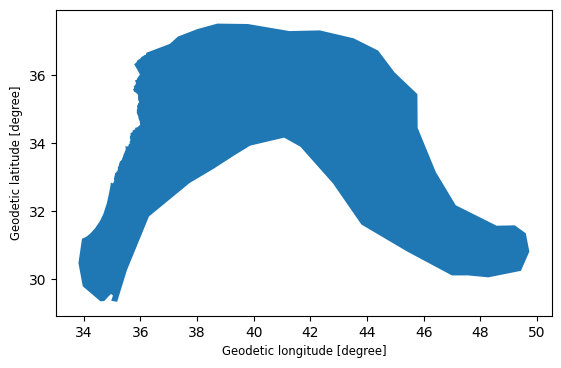

In [ ]:
# Fertile Crescent polygon
# loading the full Google Earth Project File

fertile_crescent = gpd.read_file(polygon_path)

# confirming correct shape of polygon
print(fertile_crescent)
fertile_crescent.plot()

In [ ]:
# Setting CRS of polygon and PDSI data to EPSG 4326 (global standard) using geopandas

fertile_crescent = fertile_crescent.to_crs('EPSG:4326')

# Ensure fertile_crescent is in the same CRS as PDSI using rioxarray, and setting dimensions

PDSI = PDSI.rio.set_spatial_dims(x_dim='lon', y_dim='lat')
PDSI = PDSI.rio.write_crs('EPSG:4326')
print(PDSI.rio.crs) # check if CRS is set correctly

EPSG:4326


In [ ]:
# Clipping PDSI data to fit custom polygon, ignoring cells that dont lie within

PDSI_clipped = PDSI.rio.clip([fertile_crescent.geometry.iloc[0]], fertile_crescent.crs, all_touched=True)

In [ ]:
import numpy as np

# Finding when the data actually starts to identify usable start date

# .isel pulls data out of xarray objects using index numbers, .values pulls the value as a numpy array
# np.isnan checks each value in the grid if it is NaN or not; True or False
# np.all checks if every single one of those True/False values from the grid are True
# if not: if it is not the case that every single value is True (Nan), then real data does exist and the loop ends, otherwise loop continues.

for i in range(0, len(PDSI.time), 12):
    value = PDSI_clipped['pdsi'].isel(time=i).values
    a = np.isnan(value)
    if not np.all(a):
        print("First real data at:", PDSI_clipped.time.values[i])
        break

First real data at: 1876-01-01T00:00:00.000000000


In [ ]:
# averaging PDSI values to get one value per month
regional_mean = PDSI_clipped.mean(dim=['lat','lon'], skipna = True)

In [ ]:
# creating a pandas dataframe to store values for analysis
df_pdsi = regional_mean.to_dataframe()
print(df_pdsi.head())
print(df_pdsi.tail())

            spatial_ref  pdsi
time                         
1850-01-01            0   NaN
1850-02-01            0   NaN
1850-03-01            0   NaN
1850-04-01            0   NaN
1850-05-01            0   NaN
            spatial_ref      pdsi
time                             
2014-08-01            0 -0.528439
2014-09-01            0  0.001329
2014-10-01            0  0.828134
2014-11-01            0  0.876472
2014-12-01            0  0.392709


In [ ]:
# cleaning
df_pdsi = df_pdsi.drop(columns= ['spatial_ref'])

# this will select evert row after the date 1876 till the end
df_pdsi = df_pdsi.loc['1876-01-01':]

In [ ]:
# checking for any missing months

print(df_pdsi['pdsi'].isna().sum())

0


In [ ]:
# finding the driest month

driest_date = df_pdsi['pdsi'].idxmin()
driest_value = df_pdsi['pdsi'].min()

print(driest_date)
print(driest_value)

2008-05-01 00:00:00
-4.962879180908203


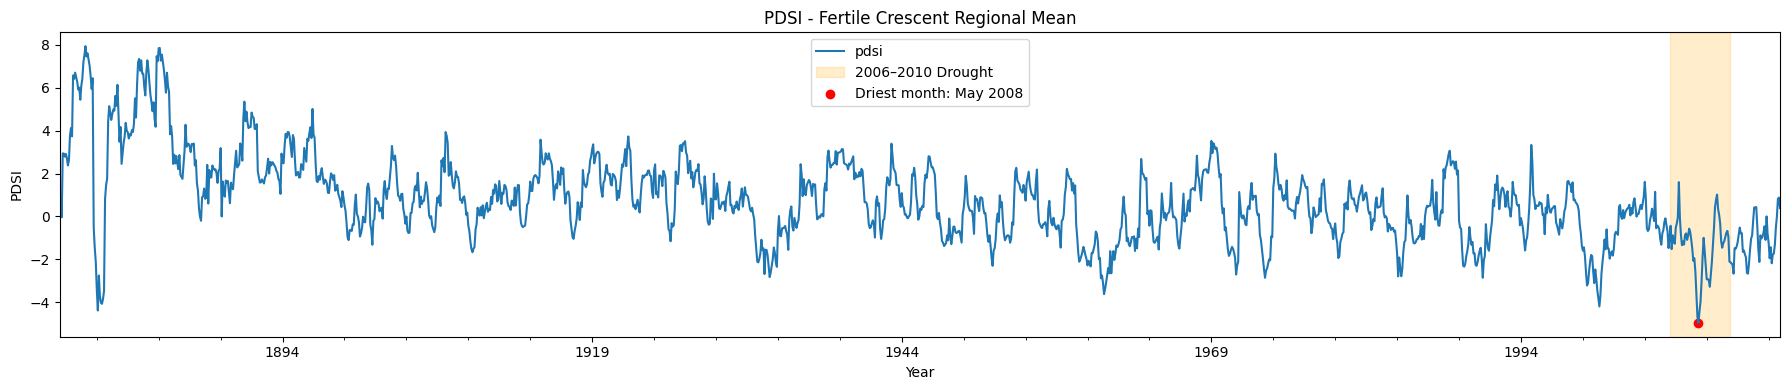

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

# creating initial plot
ax = df_pdsi.plot(y='pdsi', kind='line', figsize=(18, 4))

# highlighting the 2006-2010 drought window
ax.axvspan(pd.Timestamp('2006-01-01'), pd.Timestamp('2010-12-31'),
           color='orange', alpha=0.2, label='2006–2010 Drought')

# marking the single driest month on the record
ax.scatter( driest_date, driest_value, color='red',label=f'Driest month: {driest_date.strftime("%B %Y")}')


plt.title('PDSI - Fertile Crescent Regional Mean')
plt.xlabel('Year')
plt.ylabel('PDSI')
plt.legend()

plt.tight_layout()
plt.show()

**FAO AquaStat - Water Use**

In [ ]:
# pulling AQUASTAT data from drive

df_aqua = pd.read_csv(aqua_path)

In [ ]:
# seeing how the data is organised

print(df_aqua.head())
print(df_aqua.tail())


   m49                        VariableGroup  \
0  760  Irrigation and drainage development   
1  760  Irrigation and drainage development   
2  760  Irrigation and drainage development   
3  760  Irrigation and drainage development   
4  760  Irrigation and drainage development   

                                          Subgroup  \
0  Area equipped for irrigation by source of water   
1  Area equipped for irrigation by source of water   
2  Area equipped for irrigation by source of water   
3  Area equipped for irrigation by source of water   
4  Area equipped for irrigation by source of water   

                                      Variable                  Area  Year  \
0  Area equipped for irrigation by groundwater  Syrian Arab Republic  1993   
1  Area equipped for irrigation by groundwater  Syrian Arab Republic  1994   
2  Area equipped for irrigation by groundwater  Syrian Arab Republic  1995   
3  Area equipped for irrigation by groundwater  Syrian Arab Republic  1996   
4 

In [ ]:
# removing unnecessary columns
df_aqua = df_aqua.drop(columns=['m49','Area','VariableGroup','Subgroup','IsAggregate'])

In [ ]:
# seeing how the data is organised

print(df_aqua.head())
print(df_aqua.tail())

                                      Variable  Year       Value     Unit  \
0  Area equipped for irrigation by groundwater  1993  610.000000  1000 ha   
1  Area equipped for irrigation by groundwater  1994  633.154545  1000 ha   
2  Area equipped for irrigation by groundwater  1995  656.309091  1000 ha   
3  Area equipped for irrigation by groundwater  1996  679.463636  1000 ha   
4  Area equipped for irrigation by groundwater  1997  702.618182  1000 ha   

  Symbol  
0      A  
1      I  
2      I  
3      I  
4      I  
                   Variable  Year    Value          Unit Symbol
279  Total water withdrawal  2010  16.7604  10^9 m3/year      E
280  Total water withdrawal  2011  16.7604  10^9 m3/year      E
281  Total water withdrawal  2012  16.7604  10^9 m3/year      E
282  Total water withdrawal  2013  16.7604  10^9 m3/year      E
283  Total water withdrawal  2014  16.7604  10^9 m3/year      E


In [ ]:
# Sort by variable and year to compare consecutive observations
df_aqua = df_aqua.sort_values(
    ['Variable', 'Year']
).reset_index(drop=True)

# Flag values identical to the previous observation
# within the same AquaStat variable
df_aqua['differences'] = (df_aqua.groupby('Variable')['Value'].diff().eq(0))

# Check missing values and compare repeated values
# against AquaStat's original data flags
print(df_aqua.isna().sum())
print(pd.crosstab(df_aqua['Symbol'], df_aqua['differences']))


Variable       0
Year           0
Value          0
Unit           0
Symbol         0
differences    0
dtype: int64
differences  False  True 
Symbol                   
A               32      0
E               82     72
I               49     49


**UN Population Portal - Urbanisation**

In [ ]:
# pulling UN population data from drive

df_population = pd.read_csv(population_path)

In [ ]:
# seeing how the data is organised

print(df_population.head())
print(df_population.tail())

   IndicatorId                         IndicatorName  \
0           87  Population by degree of urbanization   
1           87  Population by degree of urbanization   
2           87  Population by degree of urbanization   
3           87  Population by degree of urbanization   
4           87  Population by degree of urbanization   

                     IndicatorShortName                        Source  \
0  Population by degree of urbanization  World Urbanization Prospects   
1  Population by degree of urbanization  World Urbanization Prospects   
2  Population by degree of urbanization  World Urbanization Prospects   
3  Population by degree of urbanization  World Urbanization Prospects   
4  Population by degree of urbanization  World Urbanization Prospects   

   SourceYear                              Author  LocationId  \
0        2025  United Nations Population Division         760   
1        2025  United Nations Population Division         760   
2        2025  United Nations

In [ ]:
df_population = df_population.drop(columns=['IndicatorId','IndicatorShortName','EstimateMethodId','EstimateTypeId','EstimateType','Iso2','Iso3','TimeId','VariantId','SexId','AgeId','AgeStart','AgeEnd','Age','CategoryId','Location','LocationId','Author','Sex','Variant'])

In [ ]:
# seeing how the data is organised

print(df_population.head())
print(df_population.tail())


                          IndicatorName                        Source  \
0  Population by degree of urbanization  World Urbanization Prospects   
1  Population by degree of urbanization  World Urbanization Prospects   
2  Population by degree of urbanization  World Urbanization Prospects   
3  Population by degree of urbanization  World Urbanization Prospects   
4  Population by degree of urbanization  World Urbanization Prospects   

   SourceYear  Time          Category EstimateMethod      Value  
0        2025  1950  Cities and towns     Projection  1523542.0  
1        2025  1951  Cities and towns     Projection  1576442.0  
2        2025  1952  Cities and towns     Projection  1632462.0  
3        2025  1953  Cities and towns     Projection  1691571.0  
4        2025  1954  Cities and towns     Projection  1753996.0  
                                         IndicatorName  \
190  Annual rate of population change by degree of ...   
191  Annual rate of population change by degree o

**FaoStat - Agricultural Output**

In [ ]:
# pulling FAOSTAT data from drive

df_fao = pd.read_csv(fao_path)

In [ ]:
# viewing data

print(df_fao.head())
print(df_fao.tail())

  Domain Code                        Domain  Area Code (M49)  \
0         QCL  Crops and livestock products              760   
1         QCL  Crops and livestock products              760   
2         QCL  Crops and livestock products              760   
3         QCL  Crops and livestock products              760   
4         QCL  Crops and livestock products              760   

                   Area  Element Code     Element  Item Code (CPC)    Item  \
0  Syrian Arab Republic          5412       Yield            115.0  Barley   
1  Syrian Arab Republic          5510  Production            115.0  Barley   
2  Syrian Arab Republic          5412       Yield            115.0  Barley   
3  Syrian Arab Republic          5510  Production            115.0  Barley   
4  Syrian Arab Republic          5412       Yield            115.0  Barley   

   Year Code  Year   Unit     Value Flag Flag Description  Note  
0       1961  1961  kg/ha     460.8    A   Official value   NaN  
1       1961  

In [ ]:
# dropping unneccesary columns

df_fao = df_fao.drop(columns=['Year Code','Flag','Note','Flag Description','Item Code (CPC)','Element Code','Area','Domain','Area Code (M49)','Domain Code'])

In [ ]:
# viewing data

print(df_fao.head())
print(df_fao.tail())

      Element    Item  Year   Unit     Value
0       Yield  Barley  1961  kg/ha     460.8
1  Production  Barley  1961      t  335000.0
2       Yield  Barley  1962  kg/ha    1103.3
3  Production  Barley  1962      t  797758.0
4       Yield  Barley  1963  kg/ha     975.9
        Element   Item  Year   Unit       Value
427  Production  Wheat  2012      t  3609096.00
428       Yield  Wheat  2013  kg/ha     2315.80
429  Production  Wheat  2013      t  3182111.00
430       Yield  Wheat  2014  kg/ha     1571.80
431  Production  Wheat  2014      t  2024332.33


**CRU TS Data - Gridded precipitation and other meteorological variables since 1901**

In [ ]:
# CRU Potential Evapotranspiration
pet = xr.open_dataset(pet_path)

# checking variable and dimension naming
print(pet)
print(pet.coords)


<xarray.Dataset> Size: 2GB
Dimensions:  (time: 1488, lat: 360, lon: 720)
Coordinates:
  * time     (time) datetime64[ns] 12kB 1901-01-16 1901-02-15 ... 2024-12-16
  * lat      (lat) float32 1kB -89.75 -89.25 -88.75 -88.25 ... 88.75 89.25 89.75
  * lon      (lon) float32 3kB -179.8 -179.2 -178.8 -178.2 ... 178.8 179.2 179.8
Data variables:
    pet      (time, lat, lon) float32 2GB ...
Attributes:
    Conventions:  CF-1.4
    title:        CRU TS4.09 Potential Evapotranspiration
    institution:  Data held at British Atmospheric Data Centre, RAL, UK.
    source:       Run ID = 2503051245. Data generated from:PET derived from m...
    history:      Wed  5 Mar 21:06:18 GMT 2025 : User f098 : Program makegrid...
    references:   Information on the data is available at http://badc.nerc.ac...
    comment:      Access to these data is available to any registered CEDA user.
    contact:      support@ceda.ac.uk
Coordinates:
  * time     (time) datetime64[ns] 12kB 1901-01-16 1901-02-15 ... 2024-

In [ ]:
# clipping evapotranspiration file

pet = pet.rio.set_spatial_dims(x_dim='lon', y_dim='lat')
pet = pet.rio.write_crs('EPSG:4326')
pet_clipped = pet.rio.clip([fertile_crescent.geometry.iloc[0]], fertile_crescent.crs, all_touched=True)

In [ ]:
# check where real data starts in this specific region (same approach as PDSI Data)
import numpy as np
for i in range(0, len(pet_clipped.time), 12):
    value = pet_clipped['pet'].isel(time=i).values
    if not np.all(np.isnan(value)):
        print("First real data in region at:", pet_clipped.time.values[i])
        break

First real data in region at: 1901-01-16T00:00:00.000000000


In [ ]:
# Creating a single regional monthly time series
pet_regional = pet_clipped.mean(dim=['lat', 'lon'], skipna=True)
df_pet = pet_regional.to_dataframe()
df_pet.head()

,spatial_ref,pet
time,,
1901-01-16,0,1.476842
1901-02-15,0,2.342807
1901-03-16,0,3.701754
1901-04-16,0,5.052631
1901-05-16,0,6.317193


In [ ]:
# drop the spatial_ref metadata column
df_pet = df_pet.drop(columns=['spatial_ref'])

# check for missing months
print(df_pet['pet'].isna().sum(), "missing months out of", len(df_pet))

print(df_pet.head())
print(df_pet.tail())

0 missing months out of 1488
                 pet
time                
1901-01-16  1.476842
1901-02-15  2.342807
1901-03-16  3.701754
1901-04-16  5.052631
1901-05-16  6.317193
                 pet
time                
2024-08-16  8.570527
2024-09-16  6.286316
2024-10-16  4.028421
2024-11-16  2.299299
2024-12-16  1.551228


In [ ]:
# CRU Temperature
tmp = xr.open_dataset(tmp_path)

# checking variable and dimension naming
print(tmp)
print(tmp.coords)

<xarray.Dataset> Size: 8GB
Dimensions:  (time: 1488, lat: 360, lon: 720)
Coordinates:
  * time     (time) datetime64[ns] 12kB 1901-01-16 1901-02-15 ... 2024-12-16
  * lat      (lat) float32 1kB -89.75 -89.25 -88.75 -88.25 ... 88.75 89.25 89.75
  * lon      (lon) float32 3kB -179.8 -179.2 -178.8 -178.2 ... 178.8 179.2 179.8
Data variables:
    tmp      (time, lat, lon) float32 2GB ...
    stn      (time, lat, lon) float64 3GB ...
    mae      (time, lat, lon) float32 2GB ...
    maea     (time, lat, lon) float32 2GB ...
Attributes:
    Conventions:  CF-1.4
    title:        CRU TS4.09 Mean Temperature
    institution:  Data held at British Atmospheric Data Centre, RAL, UK.
    source:       Run ID = 2503051245. Data generated from:tmp.2503051121.dtb
    history:      Wed  5 Mar 13:28:04 GMT 2025 : User f098 : Program makegrid...
    references:   Information on the data is available at http://badc.nerc.ac...
    comment:      Access to these data is available to any registered CEDA user

In [ ]:
# dropping unnecessary variables
tmp = tmp.drop_vars(['stn','mae','maea'])
print(tmp)
print(tmp.coords)

<xarray.Dataset> Size: 2GB
Dimensions:  (time: 1488, lat: 360, lon: 720)
Coordinates:
  * time     (time) datetime64[ns] 12kB 1901-01-16 1901-02-15 ... 2024-12-16
  * lat      (lat) float32 1kB -89.75 -89.25 -88.75 -88.25 ... 88.75 89.25 89.75
  * lon      (lon) float32 3kB -179.8 -179.2 -178.8 -178.2 ... 178.8 179.2 179.8
Data variables:
    tmp      (time, lat, lon) float32 2GB ...
Attributes:
    Conventions:  CF-1.4
    title:        CRU TS4.09 Mean Temperature
    institution:  Data held at British Atmospheric Data Centre, RAL, UK.
    source:       Run ID = 2503051245. Data generated from:tmp.2503051121.dtb
    history:      Wed  5 Mar 13:28:04 GMT 2025 : User f098 : Program makegrid...
    references:   Information on the data is available at http://badc.nerc.ac...
    comment:      Access to these data is available to any registered CEDA user.
    contact:      support@ceda.ac.uk
Coordinates:
  * time     (time) datetime64[ns] 12kB 1901-01-16 1901-02-15 ... 2024-12-16
  * lat  

In [ ]:
# clipping temperature file
tmp = tmp.rio.set_spatial_dims(x_dim='lon', y_dim='lat')
tmp = tmp.rio.write_crs('EPSG:4326')
tmp_clipped = tmp.rio.clip([fertile_crescent.geometry.iloc[0]], fertile_crescent.crs, all_touched=True)

In [ ]:
# check where real data starts in this specific region (same approach as PDSI Data)
import numpy as np
for i in range(0, len(tmp_clipped.time), 12):
    value = tmp_clipped['tmp'].isel(time=i).values
    if not np.all(np.isnan(value)):
        print("First real data in region at:", tmp_clipped.time.values[i])
        break

First real data in region at: 1901-01-16T00:00:00.000000000


In [ ]:
# Creating a  monthly time series
tmp_regional = tmp_clipped.mean(dim=['lat', 'lon'], skipna=True)
df_tmp = tmp_regional.to_dataframe()
df_tmp.head()

,spatial_ref,tmp
time,,
1901-01-16,0,7.140909
1901-02-15,0,11.290560
1901-03-16,0,15.717484
1901-04-16,0,19.538113
1901-05-16,0,23.180071


In [ ]:
# drop the spatial_ref metadata column
df_tmp = df_tmp.drop(columns=['spatial_ref'])

# check for missing months
print(df_tmp['tmp'].isna().sum(), "missing months out of", len(df_tmp))

print(df_tmp.head())
print(df_tmp.tail())

0 missing months out of 1488
                  tmp
time                 
1901-01-16   7.140909
1901-02-15  11.290560
1901-03-16  15.717484
1901-04-16  19.538113
1901-05-16  23.180071
                  tmp
time                 
2024-08-16  33.022381
2024-09-16  29.101398
2024-10-16  22.938463
2024-11-16  15.982517
2024-12-16  10.780070


In [ ]:
combined = df_tmp[['tmp']].join(df_pet[['pet']])
print(combined.head())
print(combined.tail())
print(combined.isna().sum())  # confirms no gaps introduced by join both data frames

                  tmp       pet
time                           
1901-01-16   7.140909  1.476842
1901-02-15  11.290560  2.342807
1901-03-16  15.717484  3.701754
1901-04-16  19.538113  5.052631
1901-05-16  23.180071  6.317193
                  tmp       pet
time                           
2024-08-16  33.022381  8.570527
2024-09-16  29.101398  6.286316
2024-10-16  22.938463  4.028421
2024-11-16  15.982517  2.299299
2024-12-16  10.780070  1.551228
tmp    0
pet    0
dtype: int64


**Gejkar Cave Geochemical Data**

In [ ]:
# Gejkar Cave

with open(gejkar_path, 'r', encoding='utf-8') as f:
    lines = f.readlines()

# finding where the actual data table starts
# the file has ~2000 lines of metadata (citations, descriptions, variable
# definitions) before the real data begins, so we search for the header row

for i, line in enumerate(lines):
    if line.startswith('depth_sample'):
        header_line = i
        break

# reading in just the data table, skipping the metadata header lines
df_gejkar = pd.read_csv(gejkar_path, sep='\t', skiprows=header_line, na_values='NA')

# viewing the data
print(df_gejkar.head())
print(df_gejkar.tail())

# checking for missing values in each column
print(df_gejkar.isna().sum())
# note: trace element columns (Mg/Ca, P/Ca, Sr/Ca, U/Ca) have a lot of missing
# values because the file's documentation says trace elements were only
# measured on the upper half of the sample and this is not an error

# checking that age already increases in order with no reversals
# interp_age is the AGE MODEL OUTPUT - only a small number of points along the
# stalagmite were directly dated (U-Th dating), and every other sample's age
# was estimated (interpolated) based on its depth relative to those dated points
print(df_gejkar['interp_age'].is_monotonic_increasing)

# converting years BP into a real calendar year
# BP convention counts backward from the year 1950, not from today
# interp_age is already in PLAIN years BP, so no unit conversion needed first
df_gejkar['calendar_year'] = 1950 - df_gejkar['interp_age']

print(df_gejkar[['interp_age','calendar_year']].head())
print(df_gejkar[['interp_age','calendar_year']].tail())

   depth_sample  interp_age  sample_thickness  d18O_measurement  \
0           0.0       -62.0               0.2          -3.66800   
1           0.2       -61.0               0.2          -2.81182   
2           0.4       -60.0               0.2          -2.81200   
3           0.6       -59.0               0.2          -3.34400   
4           0.8       -58.0               0.2          -2.84600   

   d13C_measurement  Mg_Ca_measurement  P_Ca_measurement  Sr_Ca_measurement  \
0         -4.691500           1.879369          0.350984           0.102557   
1         -3.900250           2.131285          0.308690           0.097340   
2         -3.900250           2.118187          0.252512           0.108745   
3         -4.079875           2.441467          0.323535           0.109605   
4         -3.634000           2.294579          0.350152           0.093743   

   U_Ca_measurement  
0          0.000059  
1          0.000058  
2          0.000049  
3          0.000053  
4          0

**Peqiin Cave Geochemical Data**

In [ ]:
# Peqiin Cave Data

with open(peqiin_path, 'r', encoding='utf-8') as f:
    lines = f.readlines()

# finding where the actual data table starts (same approach as Gejkar)

for i, line in enumerate(lines):
    if line.startswith('age_calkaBP'):
        header_line = i
        break

# reading in just the data table, skipping the metadata header lines
df_peqiin = pd.read_csv(peqiin_path, sep='\t',skiprows=header_line)

# viewing the data
print(df_peqiin.head())
print(df_peqiin.tail())

# dropping rows where age is missing, since we can't place these on a timeline
df_peqiin = df_peqiin.dropna(subset=['age_calkaBP'])

# sorting by age so the data is in chronological order
# unlike Gejkar, this file's ages were NOT already in order (confirmed below)
df_peqiin = df_peqiin.sort_values('age_calkaBP')
df_peqiin= df_peqiin.reset_index(drop=True)

# checking that age now increases in order with no reversals
print(df_peqiin['age_calkaBP'].is_monotonic_increasing)

# age_calkaBP is in THOUSANDS of years BP ("cal ka BP" = calendar kiloyears
# Before Present), so multiplying by 1000 to get plain years BP first -
# Gejkar's column was already in plain years, so it didn't need this step
df_peqiin['age_BP'] = df_peqiin['age_calkaBP'] * 1000

# converting years BP into a real calendar year
# BP convention counts backward from the year 1950
df_peqiin['calendar_year'] = 1950 - df_peqiin['age_BP']

print(df_peqiin[['age_calkaBP','age_BP','calendar_year']].head())

   age_calkaBP  d18O_vpdb  d13C_vpdb
0         14.0      -4.97     -11.23
1         14.2      -4.90     -11.49
2         14.5      -5.05     -11.48
3         15.0      -4.89     -11.58
4         15.5      -4.84     -11.70
     age_calkaBP  d18O_vpdb  d13C_vpdb
583        247.4      -5.25     -11.72
584        247.6      -5.39     -11.77
585        247.8      -5.08     -11.29
586        248.0      -5.28     -10.97
587        248.2      -5.40     -11.39
True
   age_calkaBP   age_BP  calendar_year
0         14.0  14000.0       -12050.0
1         14.2  14200.0       -12250.0
2         14.5  14500.0       -12550.0
3         15.0  15000.0       -13050.0
4         15.5  15500.0       -13550.0


**Soreq Cave Geochemical Data**

In [ ]:
# Soreq Cave
with open(soreq_path, 'r', encoding='utf-8') as f:
    lines = f.readlines()

# finding where the actual data table starts (the file has a long metadata header first)

for i, line in enumerate(lines):
    if line.startswith('age_calkaBP'):
        header_line = i
        break

# reading in just the data table, skipping the metadata header lines
df_soreq = pd.read_csv(soreq_path, sep='\t', skiprows=header_line)

# viewing the data
print(df_soreq.head())
print(df_soreq.tail())

# dropping rows where age is missing, since we can't place these on a timeline
df_soreq = df_soreq.dropna(subset=['age_calkaBP'])

# sorting by age so the data is in chronological order
df_soreq = df_soreq.sort_values('age_calkaBP')
df_soreq = df_soreq.reset_index(drop=True)

# checking that age now increases in order with no reversals
print(df_soreq['age_calkaBP'].is_monotonic_increasing)

# the age column is in THOUSANDS of years BP, so multiplying by 1000 to get plain years BP
df_soreq['age_BP'] = df_soreq['age_calkaBP'] * 1000

# converting years BP into a real calendar year
# BP convention counts backward from the year 1950, not from today
df_soreq['calendar_year'] = 1950 - df_soreq['age_BP']

print(df_soreq[['age_calkaBP','age_BP','calendar_year']].head())

   age_calkaBP  d18O_vpdb  d13C_vpdb
0         0.00      -5.25     -10.64
1         0.30      -5.30     -10.26
2         0.35      -5.05     -10.39
3         0.45      -5.42     -10.48
4         0.55      -5.62     -10.61
      age_calkaBP  d18O_vpdb  d13C_vpdb
1420        181.1      -4.03     -11.21
1421        181.4      -4.42     -10.62
1422        181.6      -3.55     -10.72
1423        182.0      -3.38     -11.23
1424        184.0      -3.04     -10.95
True
   age_calkaBP  age_BP  calendar_year
0         0.00     0.0         1950.0
1         0.30   300.0         1650.0
2         0.35   350.0         1600.0
3         0.45   450.0         1500.0
4         0.55   550.0         1400.0


# **Phase 2 - Cross-dataset Alignment**

**Gejkar Cave Binning**

In [ ]:
# binning Gejkar's d18O data into 100-year periods speleothem samples are not evenly spaced in time, since they were taken at
# whatever depth intervals the researchers happened to sample at.
# binning groups irregular cave measurements into fixed-width intervals to examine long-term variability and simplify visualisation.

bin_width = 100

# finding the earliest and latest calendar year in the data, so we know the
# full range we need to build bins across
start_year = df_gejkar['calendar_year'].min()
end_year = df_gejkar['calendar_year'].max()

# empty lists to store the results as we build each bin
bin_start_list = []
mean_d18O_list = []
min_d18O_list = []
max_d18O_list = []
count_list = []

# stepping through the whole timeline in fixed 100-year windows, one at a time
current_year = start_year
while current_year < end_year:
    next_year = current_year + bin_width

    # selecting only the rows whose calendar_year falls inside this window
    in_bin = df_gejkar[(df_gejkar['calendar_year'] >= current_year) & (df_gejkar['calendar_year'] < next_year)]

    # only recording a bin if at least one real sample actually falls inside it -
    # if a window has zero samples (e.g. inside a gap in the record), it's simply
    # skipped and won't appear as a row in the final result, rather than being
    # filled in with a fake/interpolated value
    if len(in_bin) > 0:
        bin_start_list.append(current_year)
        # the mean is our main summary value for the bin
        mean_d18O_list.append(in_bin['d18O_measurement'].mean())
        # min and max are stored too, so a short extreme event inside a bin
        # isn't silently hidden by the average alone
        min_d18O_list.append(in_bin['d18O_measurement'].min())
        max_d18O_list.append(in_bin['d18O_measurement'].max())
        # how many real samples went into this bin's average - a bin built
        # from only 1-2 samples is less reliable than one built from many
        count_list.append(len(in_bin))

    # moving forward to the next 100-year window
    current_year = next_year

# combining all the results into one dataframe, one row per bin
df_gejkar_binned = pd.DataFrame({
    'bin_start_year': bin_start_list,
    'mean_d18O': mean_d18O_list,
    'min_d18O': min_d18O_list,
    'max_d18O': max_d18O_list,
    'n_samples': count_list
})

# checking for gaps between bins
# since empty windows are skipped rather than filled in, two consecutive rows
# in our results can be further apart than bin_width if there was a stretch
# with no real samples at all. this finds exactly where that happens, so we
# know not to draw a connected line across a stretch where we have zero data,
# which would visually (and falsely) suggest we have continuous coverage there
df_gejkar_binned['gap_to_next'] = df_gejkar_binned['bin_start_year'].diff()
print("Gaps larger than expected bin width:")
print(df_gejkar_binned[df_gejkar_binned['gap_to_next'] > bin_width])

print(df_gejkar_binned)

Gaps larger than expected bin width:
   bin_start_year  mean_d18O  min_d18O  max_d18O  n_samples  gap_to_next
8           885.0  -5.296895    -6.109    -4.552         19        600.0
    bin_start_year  mean_d18O  min_d18O  max_d18O  n_samples  gap_to_next
0           -415.0  -5.375660    -6.072  -4.71700         50          NaN
1           -315.0  -5.459435    -5.924  -4.92000         46        100.0
2           -215.0  -5.097413    -5.859  -3.39000         63        100.0
3           -115.0  -5.219349    -5.716  -4.47500         43        100.0
4            -15.0  -5.417021    -5.929  -4.69100         47        100.0
5             85.0  -5.136264    -6.274  -4.09800         53        100.0
6            185.0  -4.925500    -6.134  -3.80700         48        100.0
7            285.0  -5.023864    -5.990  -4.30700         55        100.0
8            885.0  -5.296895    -6.109  -4.55200         19        600.0
9            985.0  -4.995853    -5.800  -4.25700         34        100.0
10 

**Soreq Cave Binning**

In [ ]:
# binning Soreq's d18O data into 100-year periods
# same approach as Gejkar, just using this file's own column name (d18O_vpdb)

bin_width = 100

start_year = df_soreq['calendar_year'].min()
end_year = df_soreq['calendar_year'].max()

bin_start_list = []
mean_d18O_list = []
min_d18O_list = []
max_d18O_list = []
count_list = []

current_year = start_year
while current_year <= end_year:
    next_year = current_year + bin_width

    in_bin = df_soreq[(df_soreq['calendar_year'] >= current_year) & (df_soreq['calendar_year'] < next_year)]
    in_bin = in_bin.dropna(subset=['d18O_vpdb'])

    if len(in_bin) > 0:
        bin_start_list.append(current_year)
        mean_d18O_list.append(in_bin['d18O_vpdb'].mean())
        min_d18O_list.append(in_bin['d18O_vpdb'].min())
        max_d18O_list.append(in_bin['d18O_vpdb'].max())
        count_list.append(len(in_bin))

    current_year = next_year

df_soreq_binned = pd.DataFrame({
    'bin_start_year': bin_start_list,
    'mean_d18O': mean_d18O_list,
    'min_d18O': min_d18O_list,
    'max_d18O': max_d18O_list,
    'n_samples': count_list
})

# checking for gaps between bins, same reasoning as Gejkar above
# Soreq's deep-time portion is much more sparsely sampled than its recent
# portion, so we expect to find several large gaps here, especially early on
df_soreq_binned['gap_to_next'] = df_soreq_binned['bin_start_year'].diff()
print("Gaps larger than expected bin width:")
print(df_soreq_binned[df_soreq_binned['gap_to_next'] > bin_width])

print(df_soreq_binned)

Gaps larger than expected bin width:
     bin_start_year  mean_d18O  min_d18O  max_d18O  n_samples  gap_to_next
1         -180050.0     -3.380     -3.38     -3.38          1       2000.0
2         -179650.0     -3.550     -3.55     -3.55          1        400.0
3         -179450.0     -4.420     -4.42     -4.42          1        200.0
4         -179150.0     -4.030     -4.03     -4.03          1        300.0
5         -178950.0     -4.040     -4.04     -4.04          1        200.0
..              ...        ...       ...       ...        ...          ...
889           -50.0     -5.310     -5.31     -5.31          1        300.0
890           150.0     -5.330     -5.33     -5.33          1        200.0
892           450.0     -5.480     -5.48     -5.48          1        200.0
896           950.0     -5.135     -5.20     -5.07          2        200.0
904          1950.0     -5.250     -5.25     -5.25          1        300.0

[380 rows x 6 columns]
     bin_start_year  mean_d18O  min_d18

In [ ]:
# The original 100-year bins obscured short-term drought variability.
# Gejkar in 5-year windows instead of 100-year bins to focus on drought window
# the 100-year bins average the 2006-2010 values together with 1985-2005,
# so they can't tell us whether 2006-2010 itself was extreme

# GEJKAR: Five-Year Window Analysis
# Compare 2006-2010 against earlier five-year intervals.
# Higher d18O is generally associated with drier conditions within the Gejkar record.

import numpy as np
import pandas as pd

window_width = 5
min_samples = 3
anchor_year = 2006

# Work with valid observations only
gejkar = df_gejkar[
    ['calendar_year', 'd18O_measurement']
].copy()

gejkar['calendar_year'] = pd.to_numeric(
    gejkar['calendar_year'], errors='coerce'
)
gejkar['d18O_measurement'] = pd.to_numeric(
    gejkar['d18O_measurement'], errors='coerce'
)

gejkar = gejkar.dropna(
    subset=['calendar_year', 'd18O_measurement']
).sort_values('calendar_year')

# Anchor windows so that 2006-2010 is one complete interval.
# Each window includes its start year but excludes its end.
start_year = int(np.floor(gejkar['calendar_year'].min()))

current_year = (
    anchor_year
    - window_width * ((anchor_year - start_year) // window_width + 1)
)

window_start_list = []
mean_d18O_list = []
min_d18O_list = []
max_d18O_list = []
count_list = []

# Stop at 2006-2010; exclude the incomplete post-drought window
while current_year <= anchor_year:
    next_year = current_year + window_width

    in_window = gejkar[
        (gejkar['calendar_year'] >= current_year) &
        (gejkar['calendar_year'] < next_year)
    ]

    # Only retain windows with at least 3 valid observations
    if len(in_window) >= min_samples:
        window_start_list.append(current_year)
        mean_d18O_list.append(
            in_window['d18O_measurement'].mean()
        )
        min_d18O_list.append(
            in_window['d18O_measurement'].min()
        )
        max_d18O_list.append(
            in_window['d18O_measurement'].max()
        )
        count_list.append(len(in_window))

    current_year = next_year

df_gejkar_5yr = pd.DataFrame({
    'window_start': window_start_list,
    'mean_d18O': mean_d18O_list,
    'min_d18O': min_d18O_list,
    'max_d18O': max_d18O_list,
    'n_samples': count_list
})

# COMPARE 2006-2010 AGAINST HISTORICAL WINDOWS

modern_window = df_gejkar_5yr[
    df_gejkar_5yr['window_start'] == 2006
]

if modern_window.empty:
    raise ValueError(
        "2006-2010 does not meet the minimum sample requirement."
    )

modern_mean = modern_window['mean_d18O'].iloc[0]
modern_n = modern_window['n_samples'].iloc[0]

# Exclude the modern window from its own comparison
historical_windows = df_gejkar_5yr[
    df_gejkar_5yr['window_start'] < 2006
].copy()

if historical_windows.empty:
    raise ValueError(
        "No historical five-year windows meet the sample requirement."
    )

# Percentage of retained historical windows with lower mean d18O
percent_lower = (
    historical_windows['mean_d18O'] < modern_mean
).mean() * 100

# Number of historical windows as extreme or more extreme
n_equal_or_higher = (
    historical_windows['mean_d18O'] >= modern_mean
).sum()

# RESULTS

print("GEJKAR FIVE-YEAR ANALYSIS")
print("-" * 45)

print("Modern period: 2006-2010")
print("Modern mean d18O:", round(modern_mean, 3), "‰ VPDB")
print("Modern sample count:", modern_n)

print("\nHistorical comparison:")
print("Historical windows retained:", len(historical_windows))
print("Earliest retained window:",
      int(historical_windows['window_start'].min()))
print("Latest retained window:",
      int(historical_windows['window_start'].max()))

print(
    "Windows with equal or higher mean d18O:",
    n_equal_or_higher
)

print(
    "\n2006-2010 had higher mean d18O than",
    round(percent_lower, 1),
    "% of retained historical five-year windows."
)

# SAMPLING COVERAGE CHECK


print("\nSamples per retained historical window:")
print(historical_windows['n_samples'].describe())

# Check which parts of the record have sufficient coverage.
# Group retained windows into 500-year periods.
historical_windows['period_start'] = (
    historical_windows['window_start'] // 500
) * 500

coverage = historical_windows.groupby(
    'period_start'
).agg(
    windows_retained=('window_start', 'count'),
    median_samples=('n_samples', 'median')
)

print("\nCoverage by 500-year period:")
print(coverage)


GEJKAR FIVE-YEAR ANALYSIS
---------------------------------------------
Modern period: 2006-2010
Modern mean d18O: -3.137 ‰ VPDB
Modern sample count: 5

Historical comparison:
Historical windows retained: 93
Earliest retained window: -414
Latest retained window: 2001
Windows with equal or higher mean d18O: 0

2006-2010 had higher mean d18O than 100.0 % of retained historical five-year windows.

Samples per retained historical window:
count    93.000000
mean      3.623656
std       0.721019
min       3.000000
25%       3.000000
50%       3.000000
75%       4.000000
max       6.000000
Name: n_samples, dtype: float64

Coverage by 500-year period:
              windows_retained  median_samples
period_start                                  
-500                        32             3.0
 0                          39             3.0
 1500                       21             4.0
 2000                        1             4.0


**Peqiin Cave Binning**

In [ ]:
# binning Peqiin's d18O data into 500-year periods
# Peqiin's samples are much more sparsely spaced on average than Gejkar or
# Soreq's more recent portion. when we first tried 100-year bins (matching
# the other two caves), over 90% of bins ended up with only a single sample
# in them (checked using n_samples.value_counts()) - meaning no real
# averaging was actually happening, just individual points relabeled with a
# bin year. widening the bin to 500 years, closer to this record's actual
# native sampling density, gives many more bins with 2 or more samples,
# so the averaging (and the min/max spread check) actually means something

bin_width = 500

start_year = df_peqiin['calendar_year'].min()
end_year = df_peqiin['calendar_year'].max()

bin_start_list = []
mean_d18O_list = []
min_d18O_list = []
max_d18O_list = []
count_list = []

current_year = start_year
while current_year < end_year:
    next_year = current_year + bin_width

    in_bin = df_peqiin[(df_peqiin['calendar_year'] >= current_year) & (df_peqiin['calendar_year'] < next_year)]
    in_bin = in_bin.dropna(subset=['d18O_vpdb'])

    if len(in_bin) > 0:
        bin_start_list.append(current_year)
        mean_d18O_list.append(in_bin['d18O_vpdb'].mean())
        min_d18O_list.append(in_bin['d18O_vpdb'].min())
        max_d18O_list.append(in_bin['d18O_vpdb'].max())
        count_list.append(len(in_bin))

    current_year = next_year

df_peqiin_binned = pd.DataFrame({
    'bin_start_year': bin_start_list,
    'mean_d18O': mean_d18O_list,
    'min_d18O': min_d18O_list,
    'max_d18O': max_d18O_list,
    'n_samples': count_list
})

# checking for gaps between bins (note: comparing against 500 here, not 100,
# since that's this record's bin width)
df_peqiin_binned['gap_to_next'] = df_peqiin_binned['bin_start_year'].diff()
print("Gaps larger than expected bin width:")
print(df_peqiin_binned[df_peqiin_binned['gap_to_next'] > bin_width])

print(df_peqiin_binned)

Gaps larger than expected bin width:
     bin_start_year  mean_d18O  min_d18O  max_d18O  n_samples  gap_to_next
16        -224750.0  -5.320000     -5.52     -5.20          3      14000.0
70        -196750.0  -5.540000     -5.54     -5.54          1       1500.0
78        -192250.0  -6.030000     -6.03     -6.03          1       1000.0
83        -189250.0  -5.180000     -5.18     -5.18          1       1000.0
87        -186750.0  -3.983333     -4.81     -3.57          3       1000.0
94        -182750.0  -3.130000     -3.13     -3.13          1       1000.0
101       -178250.0  -4.680000     -4.68     -4.68          1       1500.0
107       -161250.0  -4.140000     -4.14     -4.14          1      14500.0
108       -160250.0  -3.190000     -3.19     -3.19          1       1000.0
109       -157750.0  -3.150000     -3.15     -3.15          1       2500.0
110       -156250.0  -2.780000     -2.78     -2.78          1       1500.0
111       -155250.0  -2.940000     -2.94     -2.94          1  

**Speleothem Visualization - Deep Time Overview**

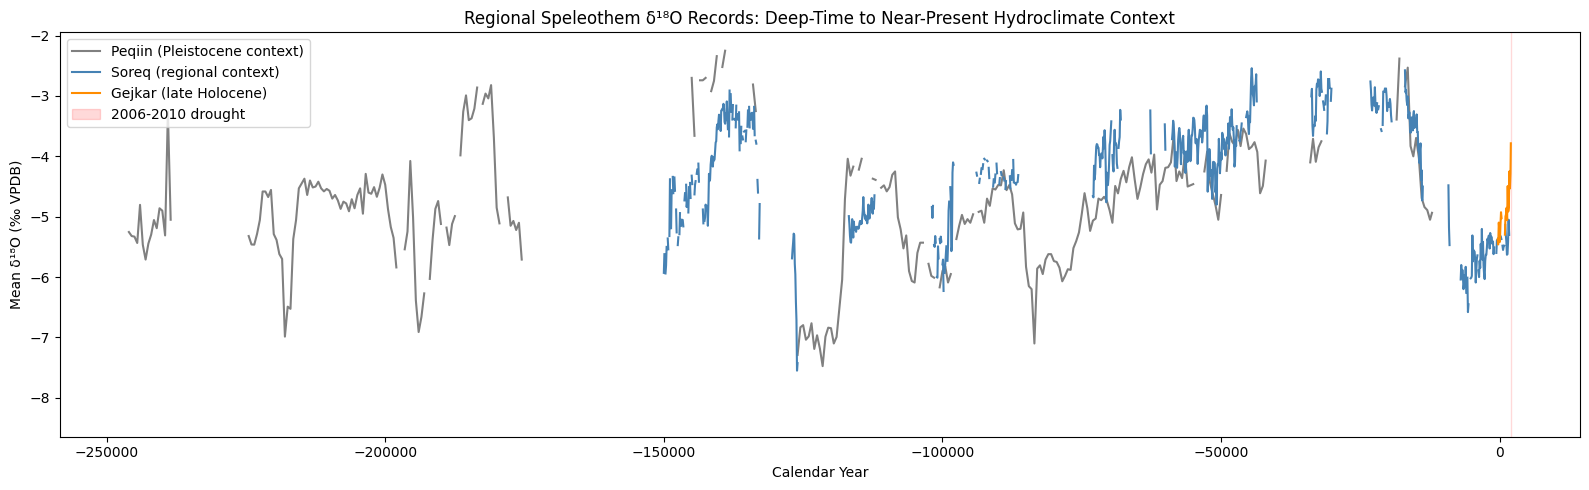

In [ ]:

import matplotlib.pyplot as plt
import numpy as np

# function to insert a NaN row wherever there's a real gap between bins, so
# matplotlib breaks the line instead of connecting periods with no data
def insert_gap_breaks(df, bin_width):
    rows = []
    for i in range(len(df)):
        rows.append(df.iloc[i])
        if i < len(df)-1:
            gap = df['bin_start_year'].iloc[i+1] - df['bin_start_year'].iloc[i]
            if gap > bin_width:
                nan_row = df.iloc[i].copy()
                nan_row['bin_start_year'] = df['bin_start_year'].iloc[i] + bin_width
                nan_row['bin_mid_year'] = nan_row['bin_start_year'] + bin_width / 2
                nan_row['mean_d18O'] = np.nan
                rows.append(nan_row)
    return pd.DataFrame(rows).reset_index(drop=True)

# plotting bins at their midpoint instead of their start year
df_gejkar_binned['bin_mid_year'] = df_gejkar_binned['bin_start_year'] + 50
df_soreq_binned['bin_mid_year'] = df_soreq_binned['bin_start_year'] + 50
df_peqiin_binned['bin_mid_year'] = df_peqiin_binned['bin_start_year'] + 250

# the final bins may be shorter than their assigned width, so using the
# actual first and last sample years to position those final points
for binned, original, width, isotope_col in [
    (df_gejkar_binned, df_gejkar, 100, 'd18O_measurement'),
    (df_soreq_binned, df_soreq, 100, 'd18O_vpdb'),
    (df_peqiin_binned, df_peqiin, 500, 'd18O_vpdb')]:
    last_start = binned['bin_start_year'].iloc[-1]
    last_samples = original.loc[
        (original['calendar_year'] >= last_start) &
        (original['calendar_year'] < last_start + width) &
        original[isotope_col].notna(), 'calendar_year']
    if len(last_samples) > 0:
        binned.loc[binned.index[-1], 'bin_mid_year'] = (last_samples.min() + last_samples.max()) / 2

g_plot = insert_gap_breaks(df_gejkar_binned, 100)
s_plot = insert_gap_breaks(df_soreq_binned, 100)
p_plot = insert_gap_breaks(df_peqiin_binned, 500)

fig, ax = plt.subplots(figsize=(16,5))

ax.plot(p_plot['bin_mid_year'], p_plot['mean_d18O'], color='gray', label='Peqiin (Pleistocene context)')
ax.plot(s_plot['bin_mid_year'], s_plot['mean_d18O'], color='steelblue', label='Soreq (regional context)')
ax.plot(g_plot['bin_mid_year'], g_plot['mean_d18O'], color='darkorange', label='Gejkar (late Holocene)')

ax.axvspan(2006, 2010, color='red', alpha=0.15, label='2006-2010 drought')

ax.set_xlabel('Calendar Year')
ax.set_ylabel('Mean δ¹⁸O (‰ VPDB)')
ax.set_title('Regional Speleothem δ¹⁸O Records: Deep-Time to Near-Present Hydroclimate Context')
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()


**Speleothem Visualization - Last 3,000 Years**

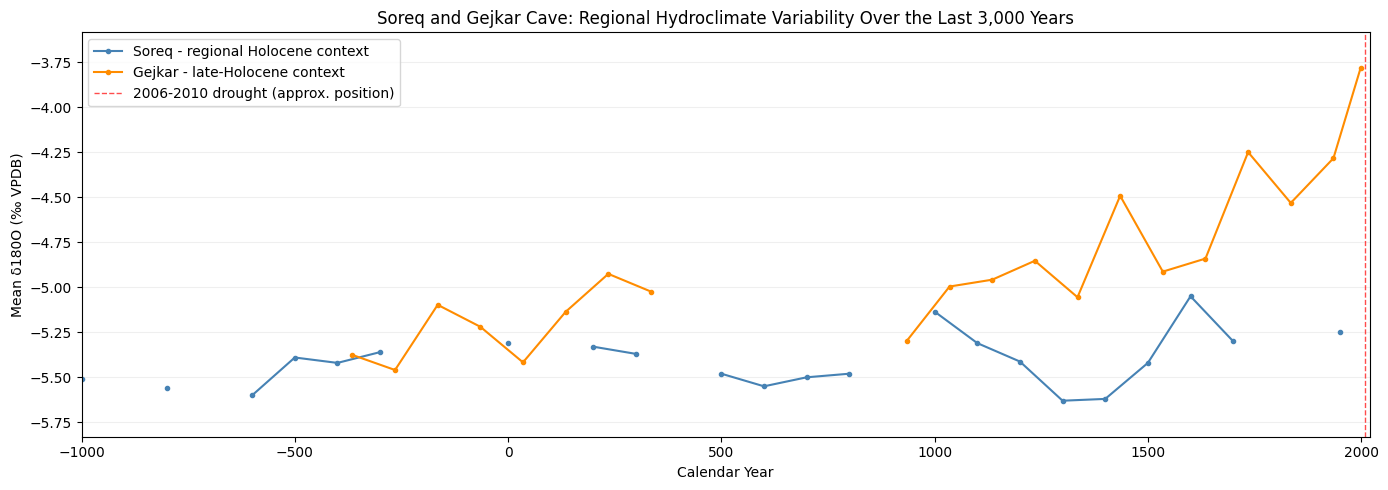

In [ ]:
import matplotlib.pyplot as plt

# Copy existing 100-year binned datasets
s = s_plot.copy()
g = g_plot.copy()

# Use nominal midpoints for full 100-year bins
s['plot_year'] = s['bin_start_year'] + 50
g['plot_year'] = g['bin_start_year'] + 50

# Correct the partially filled final bins using actual coverage
# Gejkar: final interval has samples from 1985 to 2012
g.loc[g['bin_start_year'] == 1985, 'plot_year'] = (
    1985 + 2012
) / 2

# Soreq: final observation is in 1950
s.loc[s['bin_start_year'] == 1950, 'plot_year'] = 1950

fig, ax = plt.subplots(figsize=(14, 5))

# Long-term isotope records
ax.plot(
    s['plot_year'],
    s['mean_d18O'],
    color='steelblue',
    marker='o',
    markersize=3,
    label='Soreq - regional Holocene context'
)

ax.plot(
    g['plot_year'],
    g['mean_d18O'],
    color='darkorange',
    marker='o',
    markersize=3,
    label='Gejkar - late-Holocene context'
)

# Mark the approximate timing of the modern drought
ax.axvline(
    2008,
    color='red',
    linestyle='--',
    linewidth=1,
    alpha=0.7,
    label='2006-2010 drought (approx. position)'
)

# Labels and formatting
ax.set_xlim(-1000, 2020)

# the y-axis autoscaled to the full Soreq record, so set it from the visible years only
visible = pd.concat([s, g])
visible = visible[(visible['plot_year'] >= -1000) & (visible['plot_year'] <= 2020)]
ax.set_ylim(visible['mean_d18O'].min() - 0.2, visible['mean_d18O'].max() + 0.2)

ax.set_xlabel('Calendar Year')
ax.set_ylabel('Mean δ180O (‰ VPDB)')

ax.set_title(
    'Soreq and Gejkar Cave: Regional Hydroclimate '
    'Variability Over the Last 3,000 Years'
)

ax.grid(axis='y', alpha=0.2)
ax.legend(loc='upper left')

plt.tight_layout()
plt.show()


**Gejkar Cave: Five-Year Mean δ¹⁸O and Within-Window Variability**

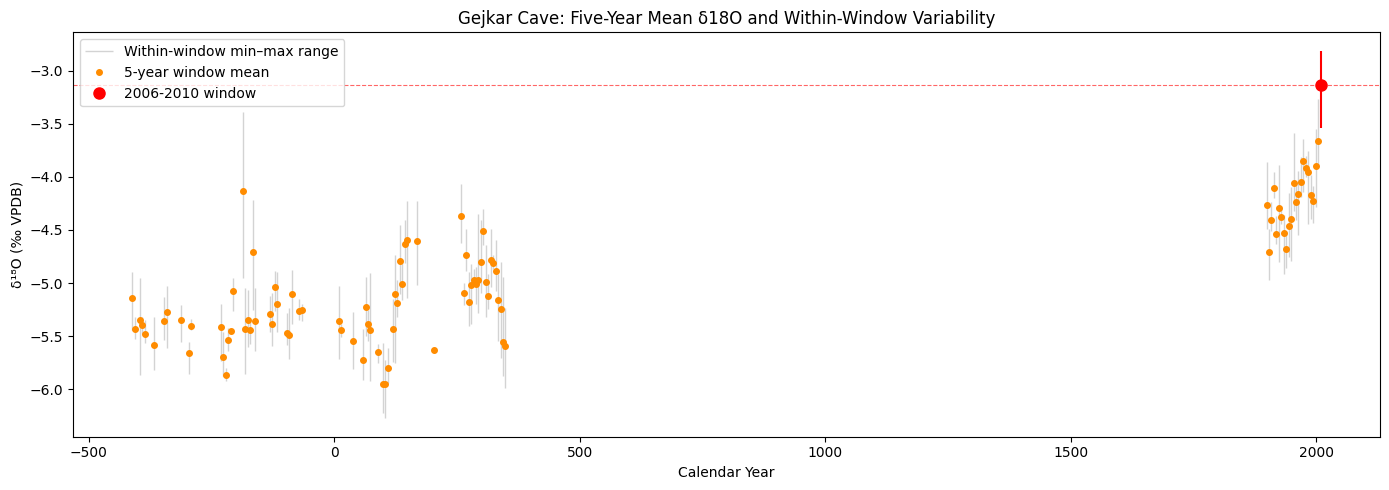

In [ ]:
import matplotlib.pyplot as plt

# plotting each window at its midpoint, not its start year, so the dot sits
# in the middle of the years it actually covers
df_gejkar_5yr['window_mid'] = df_gejkar_5yr['window_start'] + 2.5

# separating the 2006-2010 window from all the others so it can be colored differently
modern = df_gejkar_5yr[df_gejkar_5yr['window_start'] == 2006]
others = df_gejkar_5yr[df_gejkar_5yr['window_start'] != 2006]

fig, ax = plt.subplots(figsize=(14,5))

# thin gray lines show the min-max range inside each window, so a window's
# average can't hide an extreme value inside it
ax.vlines(others['window_mid'], others['min_d18O'], others['max_d18O'], color='lightgray', linewidth=1, label='Within-window min–max range')
ax.plot(others['window_mid'], others['mean_d18O'], marker='o', linestyle='none', markersize=4, color='darkorange', label='5-year window mean')

# the 2006-2010 window in red, with a dashed line across the plot at its mean
# to show whether any other window reaches that level
ax.vlines(modern['window_mid'], modern['min_d18O'], modern['max_d18O'], color='red', linewidth=1.5)
ax.plot(modern['window_mid'], modern['mean_d18O'], marker='o', linestyle='none', markersize=8, color='red', label='2006-2010 window')
ax.axhline(modern['mean_d18O'].iloc[0], color='red', linestyle='--', linewidth=0.8, alpha=0.6)

ax.set_title('Gejkar Cave: Five-Year Mean δ18O and Within-Window Variability')
ax.set_ylabel('δ¹⁸O (‰ VPDB)')
ax.set_xlabel('Calendar Year')
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()

The 2006–2010 interval has a higher mean δ18O value than all 93 earlier five-year windows that meet the minimum three-sample requirement in the Gejkar record. Because higher δ18O values are generally associated with drier conditions in this record, this suggests that 2006–2010 was unusually dry relative to the comparable portions of the Gejkar record. However, this should not be interpreted as evidence that it was the driest five-year period of the entire Holocene. The Gejkar record contains a 582-year gap from 351–933 CE and sparse sampling during parts of the later record, meaning many historical five-year periods cannot be compared at the same resolution.

# **Sensitivity Checks and Data Diagnostics**

In [ ]:
# NUMBERS CITED IN THE WEEK 11 UPDATE
# each figure quoted in the write-up is printed here so it can be traced to code

# PDSI
# how many of the region's grid cells report data at different points in time?
cells_with_data = PDSI_clipped['pdsi'].notnull().sum(dim=['lat', 'lon']).to_series()
print('Grid cells reporting in 1876, 1900, 1950:', cells_with_data.loc['1876-06-01'], cells_with_data.loc['1900-06-01'], cells_with_data.loc['1950-06-01'])

# is May 2008 still the driest month using only months where at least 75% of the cells report?
good_months = cells_with_data[cells_with_data >= 0.75 * cells_with_data.max()].index
print('Driest month with sufficient coverage:', df_pdsi.loc[df_pdsi.index.isin(good_months), 'pdsi'].idxmin())

# CRU TS
print('Temperature and PET correlation:')
print(combined.corr())

# AQUASTAT
# how many values are flagged estimated (E) or imputed (I), and how many repeat the previous recorded value?
estimated_or_imputed = df_aqua[df_aqua['Symbol'].isin(['E', 'I'])]
print('Estimated or imputed observations:', len(estimated_or_imputed))
print('Of these, repeated values:', estimated_or_imputed['differences'].sum())

# which symbols does each variable carry in 2006-2010? (only groundwater irrigation should show A)
print(df_aqua[df_aqua['Year'].between(2006, 2010)].groupby('Variable')['Symbol'].agg(lambda s: ','.join(sorted(set(s)))))

# Gejkar five-year windows
# rebuilding the windows from scratch for three different minimum-sample rules,
# to check whether the 2006-2010 result depends on that choice
gejkar_clean = df_gejkar.dropna(subset=['calendar_year', 'd18O_measurement'])
window_width = 5
anchor_year = 2006
gejkar_start = int(np.floor(gejkar_clean['calendar_year'].min()))

for min_samples in [2, 3, 4]:
    # stepping back from 2006 in whole windows so one window lands exactly on 2006-2010
    current_year = anchor_year - window_width * ((anchor_year - gejkar_start) // window_width + 1)
    window_start_list = []
    window_mean_list = []
    window_count_list = []

    while current_year <= anchor_year:
        next_year = current_year + window_width
        in_window = gejkar_clean[(gejkar_clean['calendar_year'] >= current_year) & (gejkar_clean['calendar_year'] < next_year)]
        if len(in_window) >= min_samples:
            window_start_list.append(current_year)
            window_mean_list.append(in_window['d18O_measurement'].mean())
            window_count_list.append(len(in_window))
        current_year = next_year

    windows = pd.DataFrame({'window_start': window_start_list, 'mean_d18O': window_mean_list, 'n_samples': window_count_list})
    modern_mean = windows[windows['window_start'] == 2006]['mean_d18O'].iloc[0]
    historical = windows[windows['window_start'] < 2006]

    print('Minimum samples:', min_samples)
    print('Historical windows retained:', len(historical))
    print('Historical windows equal or higher:', (historical['mean_d18O'] >= modern_mean).sum())
    print('Windows starting 933-1896:', ((historical['window_start'] >= 933) & (historical['window_start'] <= 1896)).sum())

    # keeping the three-sample version as the main result
    if min_samples == 3:
        historical_3 = historical
        modern_mean_3 = modern_mean

print('Earlier five-year windows wetter (%):', round((historical_3['mean_d18O'] < modern_mean_3).mean() * 100, 1))
print(historical_3.sort_values('mean_d18O', ascending=False).head(2))
print('Last qualifying early window:', historical_3[historical_3['window_start'] < 1000]['window_start'].max())
print('First qualifying later window:', historical_3[historical_3['window_start'] >= 1000]['window_start'].min())

# Gejkar largest gap between measurements
gejkar_sorted = gejkar_clean.sort_values('calendar_year').reset_index(drop=True)
gap_sizes = gejkar_sorted['calendar_year'].diff()
gap_row = gap_sizes.idxmax()
print('Largest gap between measurements: from', gejkar_sorted['calendar_year'].iloc[gap_row - 1], 'to', gejkar_sorted['calendar_year'].iloc[gap_row], '(', gap_sizes.max(), 'years)')

# cave files
print('Soreq missing d18O:', df_soreq['d18O_vpdb'].isna().sum())
print('Peqiin missing d18O:', df_peqiin['d18O_vpdb'].isna().sum())

Grid cells reporting in 1876, 1900, 1950: 3 16 19
Driest month with sufficient coverage: 2008-05-01 00:00:00
Temperature and PET correlation:
          tmp       pet
tmp  1.000000  0.952704
pet  0.952704  1.000000
Estimated or imputed observations: 252
Of these, repeated values: 121
Variable
Agricultural water withdrawal                                            I
Agricultural water withdrawal as % of total renewable water resources    I
Area equipped for irrigation by groundwater                              A
Area equipped for irrigation by surface water                            I
Area equipped for irrigation: total                                      E
Municipal water withdrawal                                               I
Municipal water withdrawal as % of total withdrawal                      E
SDG 6.4.2. Water Stress                                                  E
Total renewable water resources                                          E
Total water withdrawal          

## **Week 12 - Exploratory Analysis and Interactive Visualizations**



One new technique I learned for this project was how to compare an irregularly sampled paleoclimate proxy record using fixed five-year windows. My initial approach used 100-year bins, but these bins were too coarse to evaluate a drought lasting only from 2006–2010. I therefore developed a five-year window method that groups measurements into comparable intervals, calculates the mean and observed range of δ18O within each window, and excludes windows with fewer than three measurements.

The irregular spacing of the cave samples made this more complicated than the regularly spaced time-series data I had worked with previously. I used course concepts in Pandas and NumPy, documentation, and AI assistance to develop and troubleshoot the windowing approach, particularly the alignment of the windows and the minimum-sample requirement. I then tested minimum requirements of two, three, and four samples to see whether that methodological choice changed the main result.

I also learned to use Plotly to turn this analysis into an interactive visualization. Hover information allows the reader to inspect each window's dates, sample count, mean δ¹⁸O, and observed minimum–maximum range. This was useful because sampling density varies considerably through the Gejkar record, and an interactive figure makes those limitations easier to examine than a static plot alone.

In [ ]:
# Interactive Gejkar Cave Visualisation

import plotly.express as px
import numpy as np

plot_df = df_gejkar_5yr.copy()
plot_df['window_mid'] = plot_df['window_start'] + 2.5
plot_df['window_end'] = plot_df['window_start'] + 4

# separating the modern drought from historical windows
plot_df['period'] = np.where(plot_df['window_start'] == 2006, '2006-2010', 'Historical')

# calculating the distance from each mean to the minimum and maximum
# these show variability within a window, not statistical uncertainty
plot_df['upper_range'] = plot_df['max_d18O'] - plot_df['mean_d18O']
plot_df['lower_range'] = plot_df['mean_d18O'] - plot_df['min_d18O']

# taking the 2006-2010 mean from this table
modern_mean_plot = plot_df.loc[plot_df['window_start'] == 2006, 'mean_d18O'].iloc[0]

fig = px.scatter(
    plot_df,
    x='window_mid',
    y='mean_d18O',
    color='period',
    color_discrete_map={'Historical': 'darkorange', '2006-2010': 'red'},
    error_y='upper_range',
    error_y_minus='lower_range',
    hover_data={
        'window_start': True, 'window_end': True, 'n_samples': True,
        'min_d18O': ':.3f', 'max_d18O': ':.3f',
        'window_mid': False, 'upper_range': False, 'lower_range': False
    },
    labels={
        'window_mid': 'Calendar Year (negative = BCE)',
        'mean_d18O': 'Mean δ¹⁸O (‰ VPDB)',
        'period': 'Window', 'n_samples': 'Samples',
        'window_start': 'Start year', 'window_end': 'End year',
        'min_d18O': 'Minimum δ¹⁸O', 'max_d18O': 'Maximum δ¹⁸O'
    },
    title='Gejkar Cave: Five-Year Mean δ¹⁸O and Within-Window Variability'
          '<br><sup>Bars show the observed min–max range, not statistical uncertainty. '
          'Windows with fewer than 3 samples are excluded.</sup>'
)

# bigger marker for the 2006-2010 window
fig.update_traces(marker_size=7, selector=dict(name='Historical'))
fig.update_traces(marker_size=12, selector=dict(name='2006-2010'))

# dashed line at the 2006-2010 mean, with its value written on it
fig.add_hline(y=modern_mean_plot, line_dash='dash', line_color='red', opacity=0.6,
              annotation_text=f'2006-2010 mean: {modern_mean_plot:.2f}', annotation_position='top left')

# shading the period with no cave measurements at all
fig.add_vrect(x0=351, x1=933, fillcolor='gray', opacity=0.25, line_width=0,
              annotation_text='No samples', annotation_position='top left')

# shading a sparsely sampled period
# only one five-year interval meets the minimum 3-sample requirement here
fig.add_vrect(x0=933, x1=1896, fillcolor='lightgray', opacity=0.25, line_width=0,
              annotation_text='Sparse sampling', annotation_position='top left')

fig.update_layout(template='plotly_white', height=520, hovermode='closest')
fig.show()


**PDSI – Five-Year Rolling Averages and Historical Drought Comparison**

2006-2010 mean PDSI: -1.416
Historical five-year windows (overlapping): 1501
Historical windows as dry or drier: 8
Those windows end between 1962-10 and 1963-05
PDSI: historical five-year windows wetter than 2006-2010 (%): 99.5
Driest window before 2006: 1958-04 to 1963-03 | mean -1.589
Driest window in the whole record: 2007-10 to 2012-09 | mean -1.72


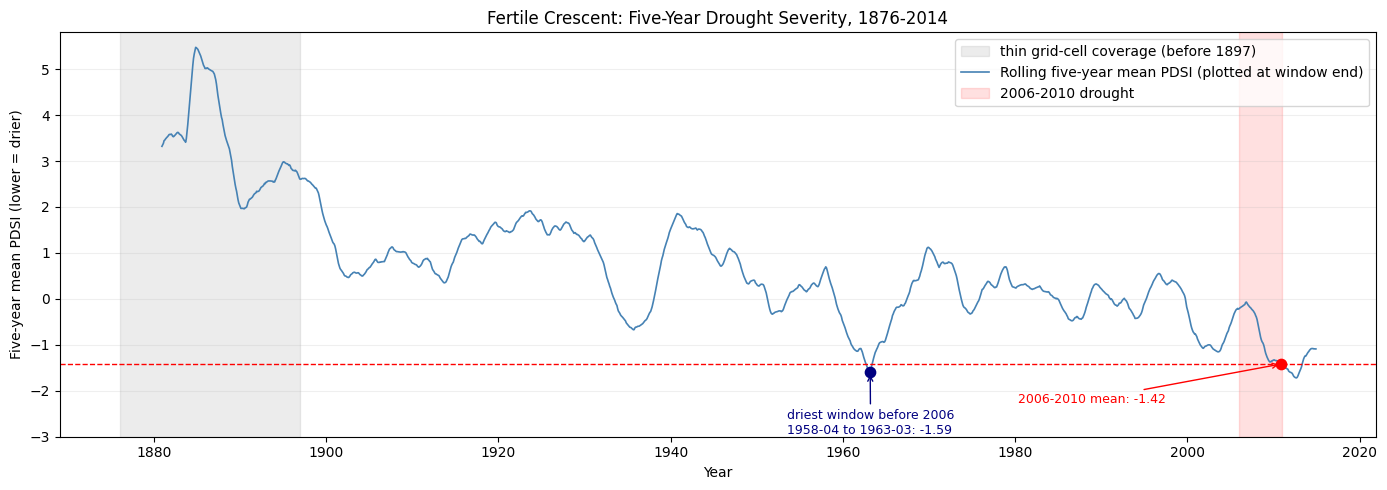

In [ ]:
# PDSI - Five Year Drought Comparison

import pandas as pd
import matplotlib.pyplot as plt

# selecting the regional monthly PDSI record
pdsi = df_pdsi['pdsi'].sort_index()

# the 2006-2010 period (named pdsi_modern so it doesn't overwrite the
# modern / modern_mean variables used in the Gejkar cells)
pdsi_modern = pdsi.loc['2006-01':'2010-12']

# checking that the modern period contains all 60 monthly observations
if len(pdsi_modern) != 60 or pdsi_modern.isna().any():
    raise ValueError('The 2006-2010 period has missing months.')

pdsi_modern_mean = pdsi_modern.mean()

# rolling five-year averages across the record
# each point is the average of that month and the previous 59 months
pdsi_5yr = pdsi.rolling(60, min_periods=60).mean().dropna()

# comparing against windows that end before the modern drought began
# these windows overlap each other, so they are not independent comparisons
historical_5yr = pdsi_5yr.loc[:'2005-12']

drier_or_equal = (historical_5yr <= pdsi_modern_mean).sum()
percent_wetter = (historical_5yr > pdsi_modern_mean).mean() * 100

# the windows that are as dry or drier - checking whether they are one episode
dry_or_drier = historical_5yr[historical_5yr <= pdsi_modern_mean]

# the driest historical window, and the driest window anywhere in the record
driest_end = historical_5yr.idxmin()
driest_start = driest_end - pd.DateOffset(months=59)
overall_end = pdsi_5yr.idxmin()
overall_start = overall_end - pd.DateOffset(months=59)

print('2006-2010 mean PDSI:', round(pdsi_modern_mean, 3))
print('Historical five-year windows (overlapping):', len(historical_5yr))
print('Historical windows as dry or drier:', drier_or_equal)
print('Those windows end between', dry_or_drier.index.min().strftime('%Y-%m'), 'and', dry_or_drier.index.max().strftime('%Y-%m'))
print('PDSI: historical five-year windows wetter than 2006-2010 (%):', round(percent_wetter, 1))
print('Driest window before 2006:', driest_start.strftime('%Y-%m'), 'to', driest_end.strftime('%Y-%m'), '| mean', round(historical_5yr.min(), 3))
print('Driest window in the whole record:', overall_start.strftime('%Y-%m'), 'to', overall_end.strftime('%Y-%m'), '| mean', round(pdsi_5yr.min(), 3))


# VISUALISING FIVE-YEAR DROUGHT SEVERITY

fig, ax = plt.subplots(figsize=(14,5))

# shading the early years, when few of the region's 19 grid cells report data
ax.axvspan(pd.Timestamp('1876-01-01'), pd.Timestamp('1897-01-01'),
           color='gray', alpha=0.15, label='thin grid-cell coverage (before 1897)')

ax.plot(pdsi_5yr.index, pdsi_5yr, color='steelblue', linewidth=1.2,
        label='Rolling five-year mean PDSI (plotted at window end)')

# highlighting the modern drought period
ax.axvspan(pd.Timestamp('2006-01-01'), pd.Timestamp('2010-12-31'),
           color='red', alpha=0.12, label='2006-2010 drought')

# the modern mean as a reference line, with a labeled point
ax.axhline(pdsi_modern_mean, color='red', linestyle='--', linewidth=1)
ax.scatter(pd.Timestamp('2010-12-01'), pdsi_modern_mean, color='red', s=55, zorder=5)
ax.annotate('2006-2010 mean: ' + str(round(pdsi_modern_mean, 2)),
            xy=(pd.Timestamp('2010-12-01'), pdsi_modern_mean),
            xytext=(-190, -28), textcoords='offset points', color='red', fontsize=9,
            arrowprops=dict(arrowstyle='->', color='red'))

# marking the driest window before 2006 for comparison
ax.scatter(driest_end, historical_5yr.min(), color='navy', s=55, zorder=5)
ax.annotate('driest window before 2006\n' + driest_start.strftime('%Y-%m') + ' to ' + driest_end.strftime('%Y-%m') + ': ' + str(round(historical_5yr.min(), 2)),
            xy=(driest_end, historical_5yr.min()),
            xytext=(-60, -45), textcoords='offset points', color='navy', fontsize=9,
            arrowprops=dict(arrowstyle='->', color='navy'))

ax.set_xlabel('Year')
ax.set_ylabel('Five-year mean PDSI (lower = drier)')
ax.set_title('Fertile Crescent: Five-Year Drought Severity, 1876-2014')
ax.set_ylim(-3.0, 5.8)
ax.legend(loc='upper right')
ax.grid(axis='y', alpha=0.2)

plt.tight_layout()
plt.show()

**FAOSTAT – Historical Agricultural Yields and the 2006–2010 Drought**

In [ ]:
# viewing the crop names, measurements, and units
print(df_fao[['Item', 'Element', 'Unit']].drop_duplicates().to_string(index=False))

                 Item    Element  Unit
               Barley      Yield kg/ha
               Barley Production     t
         Lentils, dry      Yield kg/ha
         Lentils, dry Production     t
Seed cotton, unginned      Yield kg/ha
Seed cotton, unginned Production     t
                Wheat      Yield kg/ha
                Wheat Production     t


In [ ]:
# FAOSTAT - Final Data Check

import pandas as pd

crops = ['Wheat', 'Barley', 'Lentils, dry', 'Seed cotton, unginned']

# selecting the four crops and both measurements
fao = df_fao[
    (df_fao['Item'].isin(crops)) &
    (df_fao['Element'].isin(['Yield', 'Production']))
].copy()

# checking that years and values are numeric
fao['Year'] = pd.to_numeric(fao['Year'], errors='coerce')
fao['Value'] = pd.to_numeric(fao['Value'], errors='coerce')

# checking missing and duplicate records
print('Total rows:', len(fao))
print('Year range:', fao['Year'].min(), 'to', fao['Year'].max())
print('Missing values:', fao['Value'].isna().sum())
print('Missing years:', fao['Year'].isna().sum())
print('Duplicate crop-year-measurement records:',
      fao.duplicated(subset=['Item', 'Element', 'Year']).sum())
print('Zero or negative values:', (fao['Value'] <= 0).sum())

# checking the year coverage for each crop and measurement
summary = fao.groupby(['Item', 'Element', 'Unit']).agg(
    first_year=('Year', 'min'),
    last_year=('Year', 'max'),
    years=('Year', 'nunique'),
    missing=('Value', lambda x: x.isna().sum())
)

print('\nCoverage by crop and measurement:')
print(summary.to_string())


Total rows: 432
Year range: 1961 to 2014
Missing values: 0
Missing years: 0
Duplicate crop-year-measurement records: 0
Zero or negative values: 0

Coverage by crop and measurement:
                                        first_year  last_year  years  missing
Item                  Element    Unit                                        
Barley                Production t            1961       2014     54        0
                      Yield      kg/ha        1961       2014     54        0
Lentils, dry          Production t            1961       2014     54        0
                      Yield      kg/ha        1961       2014     54        0
Seed cotton, unginned Production t            1961       2014     54        0
                      Yield      kg/ha        1961       2014     54        0
Wheat                 Production t            1961       2014     54        0
                      Yield      kg/ha        1961       2014     54        0


In [ ]:
# FAOSTAT - Comparing Agricultural Yields & Comparison

import pandas as pd

crops = ['Wheat', 'Barley', 'Lentils, dry', 'Seed cotton, unginned']

# selecting the four crops and both measurements
fao = df_fao[
    (df_fao['Item'].isin(crops)) &
    (df_fao['Element'].isin(['Yield', 'Production']))
].copy()

# separating yield and production into annual tables
yield_table = fao[fao['Element'] == 'Yield'].pivot(
    index='Year', columns='Item', values='Value'
)[crops]

production_table = fao[fao['Element'] == 'Production'].pivot(
    index='Year', columns='Item', values='Value'
)[crops]

# calculating average yields before and during the drought
yield_before = yield_table.loc[2001:2005].mean()
yield_during = yield_table.loc[2006:2010].mean()

yield_change = (yield_during - yield_before) / yield_before * 100

# identifying each crop's lowest yield during the drought
lowest_yield = yield_table.loc[2006:2010].min()
lowest_year = yield_table.loc[2006:2010].idxmin()

# comparing the lowest yield with the 2001-2005 baseline
worst_vs_baseline = (lowest_yield - yield_before) / yield_before * 100

# comparing average total production before and during the drought
production_before = production_table.loc[2001:2005].mean()
production_during = production_table.loc[2006:2010].mean()

production_change = (production_during - production_before) / production_before * 100

# testing a longer pre-drought baseline (1996-2005)
yield_before_10yr = yield_table.loc[1996:2005].mean()
yield_change_10yr = (yield_during - yield_before_10yr) / yield_before_10yr * 100

# calculating implied harvested area from annual production and yield
# production is in tonnes, yield is in kg/ha
area_table = production_table * 1000 / yield_table

area_before = area_table.loc[2001:2005].mean()
area_during = area_table.loc[2006:2010].mean()

area_change = (area_during - area_before) / area_before * 100

# bringing all results together into one summary table
fao_summary = pd.DataFrame({
    'Yield before (kg/ha)': yield_before,
    'Yield during (kg/ha)': yield_during,
    'Yield change (%)': yield_change,
    'Lowest drought year': lowest_year,
    'Lowest drought yield (kg/ha)': lowest_yield,
    'Lowest year vs baseline (%)': worst_vs_baseline,
    'Production change (%)': production_change,
    'Implied area change (%)': area_change,
    'Yield change, 10yr baseline (%)': yield_change_10yr
})

fao_summary.index.name = 'Crop'

print(fao_summary.round(1).to_string())


                       Yield before (kg/ha)  Yield during (kg/ha)  Yield change (%)  Lowest drought year  Lowest drought yield (kg/ha)  Lowest year vs baseline (%)  Production change (%)  Implied area change (%)  Yield change, 10yr baseline (%)
Crop                                                                                                                                                                                                                                                
Wheat                                2665.4                2225.2             -16.5                 2008                        1439.7                        -46.0                  -24.3                    -10.3                             -5.3
Barley                                548.5                 555.7               1.3                 2008                         182.2                        -66.8                    8.2                      8.0                              1.8
Lentils, dry        

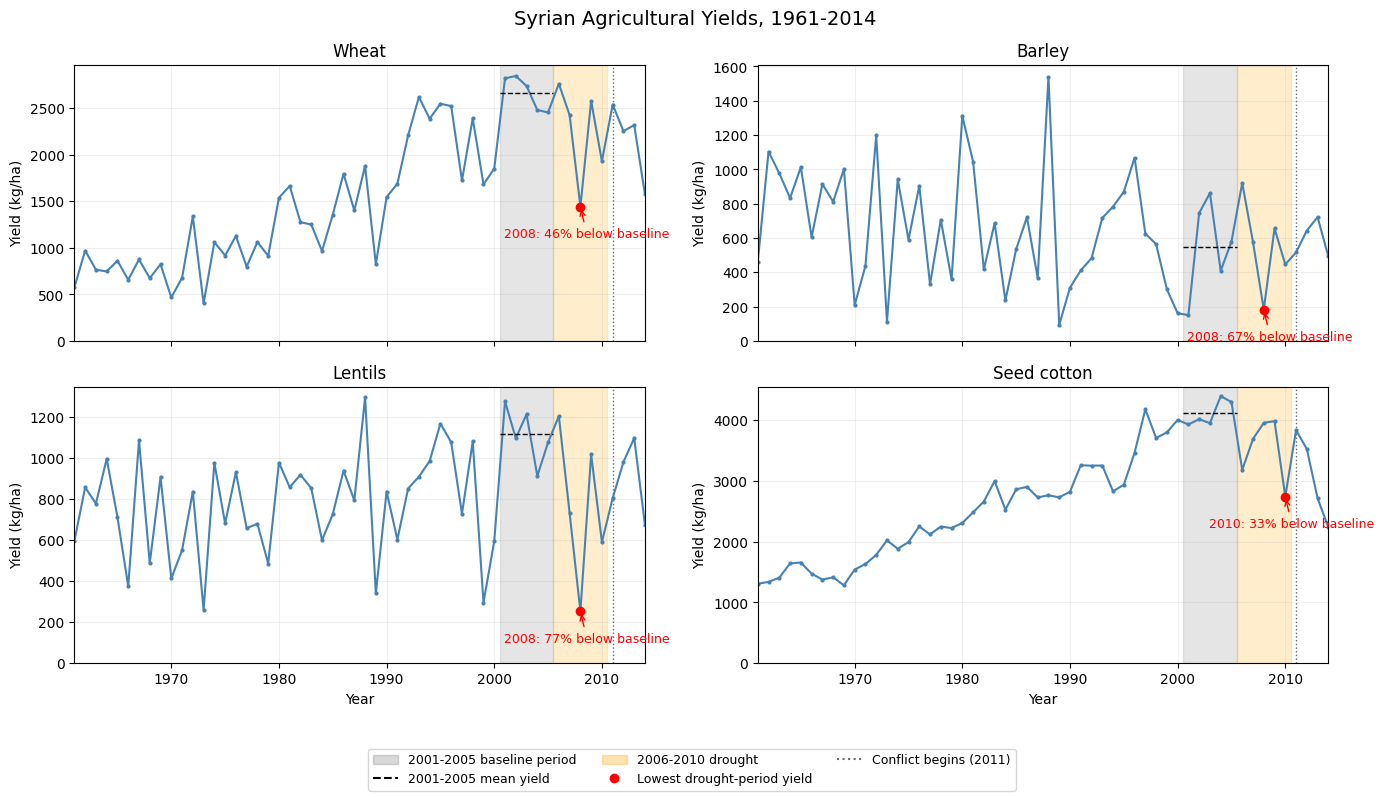

In [ ]:
# FAOSTAT - Historical Agricultural Yields

import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

# 2001-2005 pre-drought average for each crop
crop_baseline = yield_table.loc[2001:2005].mean()

crop_labels = {
    'Wheat': 'Wheat',
    'Barley': 'Barley',
    'Lentils, dry': 'Lentils',
    'Seed cotton, unginned': 'Seed cotton'
}

fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True)

for ax, crop in zip(axes.flat, crops):

    # full historical yield record
    ax.plot(
        yield_table.index,
        yield_table[crop],
        color='steelblue',
        linewidth=1.5,
        marker='o',
        markersize=2
    )

    # pre-drought baseline period and its mean
    ax.axvspan(2000.5, 2005.5, color='gray', alpha=0.2)
    ax.hlines(
        crop_baseline[crop],
        2000.5,
        2005.5,
        color='black',
        linestyle='--',
        linewidth=1
    )

    # drought period
    ax.axvspan(2005.5, 2010.5, color='orange', alpha=0.2)

    # beginning of conflict
    ax.axvline(
        2011,
        color='dimgray',
        linestyle=':',
        linewidth=1
    )

    # lowest yield during the drought
    worst_year = yield_table.loc[2006:2010, crop].idxmin()
    worst = yield_table.loc[worst_year, crop]
    pct_below = (1 - worst / crop_baseline[crop]) * 100

    ax.scatter(
        worst_year,
        worst,
        color='red',
        zorder=5
    )

    ax.annotate(
        f'{worst_year}: {pct_below:.0f}% below baseline',
        xy=(worst_year, worst),
        xytext=(-55, -22),
        textcoords='offset points',
        color='red',
        fontsize=9,
        arrowprops=dict(
            arrowstyle='->',
            color='red'
        )
    )

    ax.set_title(crop_labels[crop])
    ax.set_ylabel('Yield (kg/ha)')
    ax.set_xlim(1961, 2014)
    ax.set_ylim(bottom=0)
    ax.grid(alpha=0.2)

for ax in axes[1]:
    ax.set_xlabel('Year')

legend_items = [
    Patch(
        color='gray',
        alpha=0.3,
        label='2001-2005 baseline period'
    ),
    Line2D(
        [0], [0],
        color='black',
        linestyle='--',
        label='2001-2005 mean yield'
    ),
    Patch(
        color='orange',
        alpha=0.3,
        label='2006-2010 drought'
    ),
    Line2D(
        [0], [0],
        color='red',
        marker='o',
        linestyle='',
        label='Lowest drought-period yield'
    ),
    Line2D(
        [0], [0],
        color='dimgray',
        linestyle=':',
        label='Conflict begins (2011)'
    )
]

fig.legend(
    handles=legend_items,
    loc='lower center',
    ncol=3,
    fontsize=9
)

fig.suptitle(
    'Syrian Agricultural Yields, 1961-2014',
    fontsize=14
)

plt.tight_layout(rect=[0, 0.09, 1, 1])
plt.show()

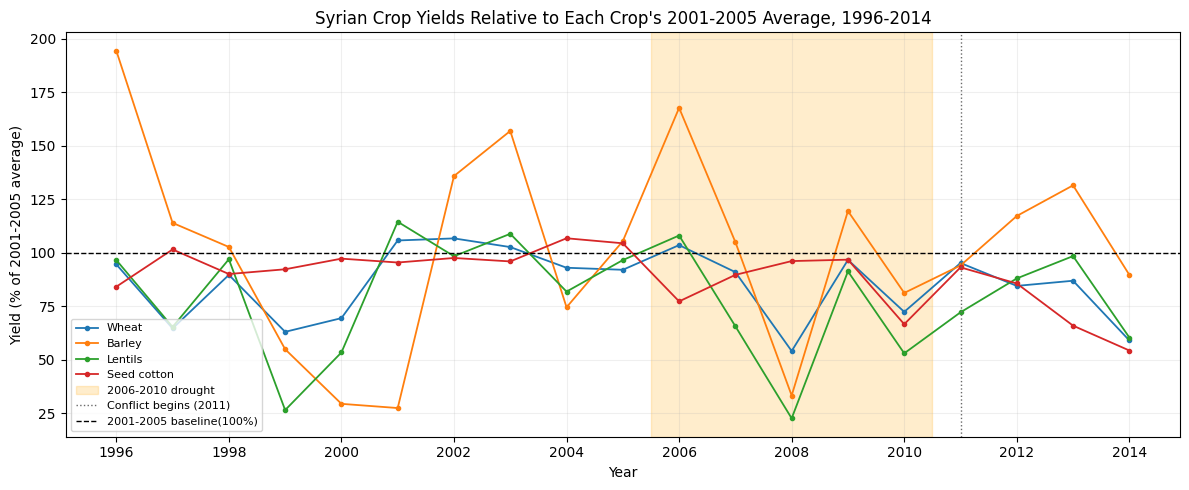

In [ ]:
# FAOSTAT - Yields Compared With Each Crop's Own Baseline

# calculating each crop's 2001-2005 average
crop_baseline = yield_table.loc[2001:2005].mean()

# expressing annual yield as a percentage of each crop's own baseline
# allows crops with very different absolute yields to be compared
yield_index = yield_table.div(crop_baseline) * 100

fig, ax = plt.subplots(figsize=(12, 5))

for crop in crops:
    ax.plot(
        yield_index.loc[1996:2014].index,
        yield_index.loc[1996:2014, crop],
        marker='o',
        markersize=3,
        linewidth=1.3,
        label=crop_labels[crop]
    )

# highlighting the drought period
ax.axvspan(
    2005.5, 2010.5,
    color='orange',
    alpha=0.2,
    label='2006-2010 drought'
)

# distinguishing the later conflict period
ax.axvline(
    2011,
    color='dimgray',
    linestyle=':',
    linewidth=1,
    label='Conflict begins (2011)'
)

# each crop's pre-drought baseline
ax.axhline(
    100,
    color='black',
    linestyle='--',
    linewidth=1,
    label='2001-2005 baseline(100%)'
)

ax.set_xticks(range(1996, 2015, 2))
ax.set_xlabel('Year')
ax.set_ylabel('Yield (% of 2001-2005 average)')
ax.set_title(
    "Syrian Crop Yields Relative to Each Crop's 2001-2005 Average, 1996-2014"
)

ax.legend(fontsize=8, loc='lower left')
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

## **FAOSTAT – Agricultural Yield and Production Analysis**

To investigate how Syrian agriculture changed during the 2006–2010 drought, I examined annual yield (kg/ha) and production (tonnes) for wheat, barley, lentils, and seed cotton between 1961 and 2014.

I used **2001–2005 as the main pre-drought baseline**, comparing its average annual yield and production with the 2006–2010 average. Using equal five-year periods makes the comparison consistent and reduces dependence on individual harvest years. However, the 2001–2005 baseline does not necessarily represent normal agricultural conditions, so I also tested a longer 1996–2005 baseline to examine how sensitive the results were to the selected comparison period.

I created two visualizations. The first shows the complete historical yield records to examine long-term trends and fluctuations. The second normalizes each crop's annual yield to its own 2001–2005 average (set to 100), allowing relative changes across crops with different absolute yields to be compared.

The summary table reports average yield and production changes, each crop's lowest-yield year during the drought, and that year's percentage difference from the baseline. I also estimated annual harvested area by dividing production (converted to kilograms) by yield (kg/ha), then compared the average implied area between the two five-year periods.

These comparisons describe agricultural changes coinciding with the drought. They do not isolate the effects of drought from irrigation, agricultural policies, changing harvested area, or longer-term developments in farming practices.

## **Temperature & Potential Evapotranspiration (Pet) Analysis**

In [ ]:
# CRU - Temp and Pet Comparison

import pandas as pd
import numpy as np

# Map the existing 'combined' DataFrame to 'cru'
cru = combined.copy()

# converting monthly PET from mm/day to mm/month
cru['pet_mm'] = cru['pet'] * cru.index.days_in_month

# selecting the common climate reference period
baseline = cru.loc['1961-01':'1990-12']

# calculating typical conditions for each calendar month
temp_climatology = baseline.groupby(
    baseline.index.month
)['tmp'].mean()

pet_climatology = baseline.groupby(
    baseline.index.month
)['pet_mm'].mean()

# calculating monthly departures from the reference period
cru['temp_anomaly'] = (
    cru['tmp'] - cru.index.month.map(temp_climatology).to_numpy()
)

cru['pet_anomaly'] = (
    cru['pet_mm'] - cru.index.month.map(pet_climatology).to_numpy()
)

# calculating the 90th percentile for each calendar month
temp_p90 = baseline.groupby(
    baseline.index.month
)['tmp'].quantile(0.90)

pet_p90 = baseline.groupby(
    baseline.index.month
)['pet_mm'].quantile(0.90)

# identifying exceptionally warm and high-PET months
cru['warm_month'] = (
    cru['tmp'] > cru.index.month.map(temp_p90).to_numpy()
)

cru['high_pet_month'] = (
    cru['pet_mm'] > cru.index.month.map(pet_p90).to_numpy()
)

# selecting the two 60-month drought periods
earlier_cru = cru.loc['1958-04':'1963-03']
modern_cru = cru.loc['2006-01':'2010-12']

# annual average PET during the reference period
baseline_pet_annual = baseline['pet_mm'].sum() / 30

# summarizing the conditions during each drought
def drought_summary(period):

    pet_anomaly_annual = period['pet_anomaly'].sum() / 5

    return {
        'Mean temperature (C)': period['tmp'].mean(),
        'Temperature anomaly (C)': period['temp_anomaly'].mean(),
        'PET (mm/year)': period['pet_mm'].sum() / 5,
        'PET anomaly (mm/year)': pet_anomaly_annual,
        'PET anomaly (%)': (
            pet_anomaly_annual / baseline_pet_annual * 100
        ),
        'Exceptionally warm months': period['warm_month'].sum(),
        'Exceptionally high-PET months': period['high_pet_month'].sum()
    }

# creating the comparison table
cru_summary = pd.DataFrame({
    '1958-04 to 1963-03': drought_summary(earlier_cru),
    '2006-01 to 2010-12': drought_summary(modern_cru)
}).T

# calculating the absolute differences between droughts
cru_summary.loc['Modern minus earlier'] = (
    cru_summary.iloc[1] - cru_summary.iloc[0]
)

print('CRU DROUGHT COMPARISON')
print(cru_summary.round(2).to_string())

# calculating the relative change in PET between droughts
pet_difference_percent = (
    (modern_cru['pet_mm'].sum() / earlier_cru['pet_mm'].sum()) - 1
) * 100

print('\nModern PET relative to earlier drought (%):',
      round(pet_difference_percent, 1))


# HISTORICAL FIVE-YEAR COMPARISONS

# calculating rolling 60-month temperature and PET values
temp_5yr = cru['tmp'].rolling(
    60, min_periods=60
).mean().dropna()

pet_5yr = cru['pet_mm'].rolling(
    60, min_periods=60
).sum().dropna() / 5

# comparing against windows ending before January 2006
historical_temp = temp_5yr.loc[:'2005-12']
historical_pet = pet_5yr.loc[:'2005-12']

# recording how unusual the modern drought period was
ranking_rows = []

comparisons = [
    ('Temperature (C)', historical_temp,
     modern_cru['tmp'].mean()),
    ('PET (mm/year)', historical_pet,
     modern_cru['pet_mm'].sum() / 5)
]

for variable, historical, modern_value in comparisons:

    # counting earlier windows as high or higher
    as_high_or_higher = (historical >= modern_value).sum()

    # calculating the percentage of earlier windows lower
    percent_lower = (historical < modern_value).mean() * 100

    # identifying the highest earlier five-year window
    highest_end = historical.idxmax()
    highest_start = highest_end - pd.DateOffset(months=59)

    ranking_rows.append({
        'Variable': variable,
        'Modern value': modern_value,
        'Earlier windows': len(historical),
        'Earlier as high/higher': as_high_or_higher,
        'Earlier windows lower (%)': percent_lower,
        'Highest earlier window': (
            highest_start.strftime('%Y-%m') + ' to ' +
            highest_end.strftime('%Y-%m')
        ),
        'Highest earlier value': historical.max()
    })

historical_ranking = pd.DataFrame(
    ranking_rows
).set_index('Variable')

print('\nHISTORICAL FIVE-YEAR RANKING')
print(historical_ranking.round(2).to_string())

CRU DROUGHT COMPARISON
                      Mean temperature (C)  Temperature anomaly (C)  PET (mm/year)  PET anomaly (mm/year)  PET anomaly (%)  Exceptionally warm months  Exceptionally high-PET months
1958-04 to 1963-03                   20.32                     0.37        1795.02                  31.72             1.80                       12.0                           13.0
2006-01 to 2010-12                   21.21                     1.26        1826.01                  62.71             3.56                       35.0                           21.0
Modern minus earlier                  0.90                     0.90          30.99                  30.99             1.76                       23.0                            8.0

Modern PET relative to earlier drought (%): 1.7

HISTORICAL FIVE-YEAR RANKING
                 Modern value  Earlier windows  Earlier as high/higher  Earlier windows lower (%) Highest earlier window  Highest earlier value
Variable                      

### **CRU Temperature and Potential Evapotranspiration – Historical and Seasonal Comparison**

To investigate the climatic conditions accompanying the two severe droughts, I analyzed monthly regional temperature and potential evapotranspiration (PET) from CRU TS v4.09, covering 1901–2024. The data were clipped to my Fertile Crescent study region and spatially averaged to create monthly regional time series.

I compared two **60-month periods**: April 1958–March 1963, identified as the driest earlier five-year interval in the regional PDSI analysis, and January 2006–December 2010. Using equal-length periods ensures that both comparisons include five observations of every calendar month.

I selected **1961–1990 as a common 30-year climatological reference period**. For each month, I calculated temperature and PET anomalies relative to the corresponding calendar month's historical average. This reference is retrospective and overlaps with part of the earlier drought. It allows both droughts to be evaluated against the same seasonal averages, but does not establish how unusual each drought was relative to the climate immediately preceding it.

I also identified exceptionally warm and high-PET months using the 90th percentile for each calendar month during 1961–1990. To assess historical unusualness, I compared the modern drought against all overlapping 60-month periods ending before January 2006. These overlapping windows are not independent observations.

Temperature was analyzed in degrees Celsius. Because PET was reported in mm/day, I multiplied each monthly value by the number of days in that month before calculating monthly totals and annual-equivalent PET in millimetres.

Finally, I plotted annual mean temperature and annual total PET for 1901–2024 and calculated descriptive linear trends using NumPy. I also compared monthly temperature and PET anomalies to identify seasonal differences between the droughts.

The analysis describes regional temperature and potential atmospheric evaporative demand. PET does not measure actual evaporation, and these variables alone cannot establish the causes or agricultural effects of either drought.

temperature trend per decade: 0.14
pet_total trend per decade: 5.61


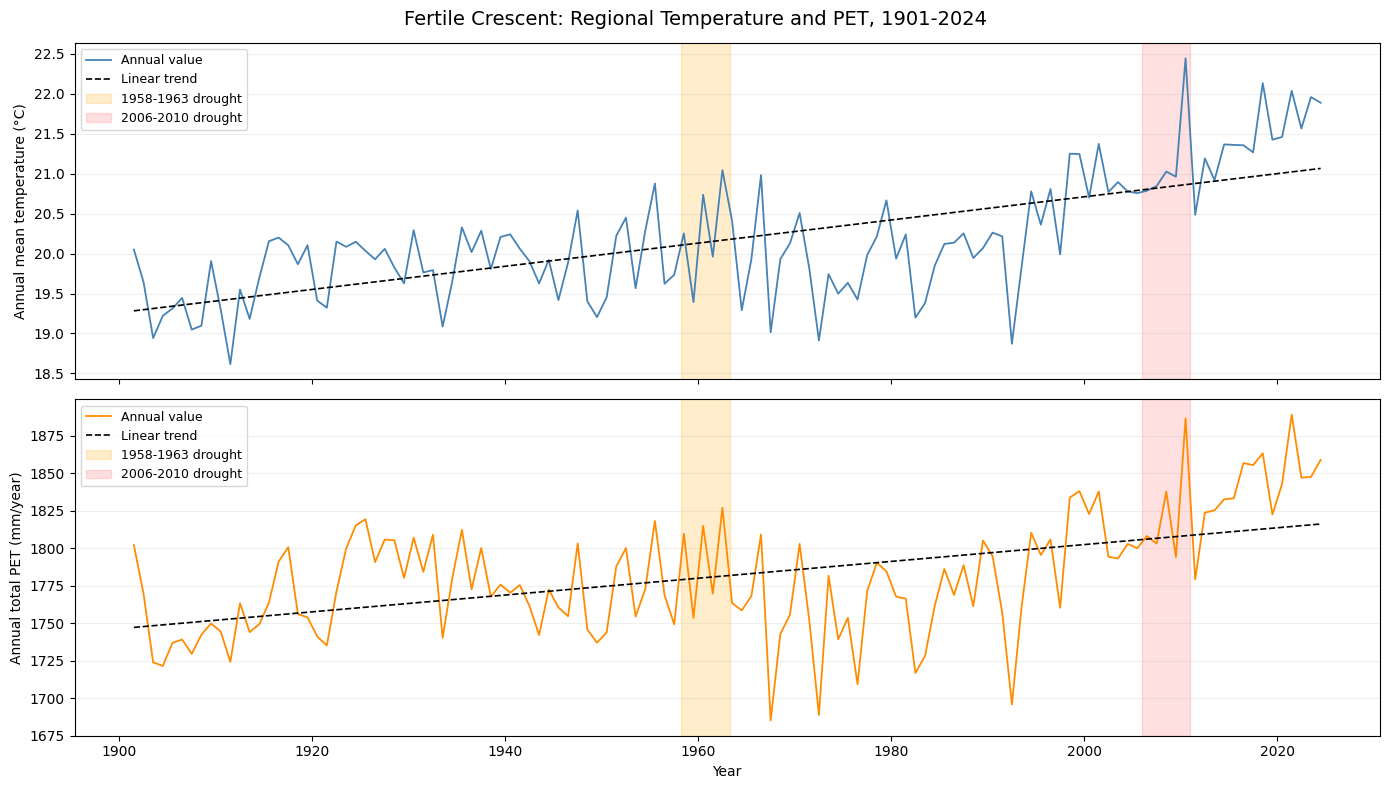

In [ ]:
# CRU - Long term Temp & Pet (1901-2024)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# calculating annual mean temperature and annual total PET
annual_cru = cru.groupby(cru.index.year).agg(
    temperature=('tmp', 'mean'),
    pet_total=('pet_mm', 'sum')
)

# plotting annual observations at the middle of each year
annual_dates = pd.to_datetime(
    annual_cru.index.astype(str) + '-07-01'
)

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

variables = [
    ('temperature', 'Annual mean temperature (°C)', 'steelblue'),
    ('pet_total', 'Annual total PET (mm/year)', 'darkorange')
]

for ax, (column, ylabel, color) in zip(axes, variables):

    # plotting the historical annual record
    ax.plot(annual_dates, annual_cru[column],
            color=color, linewidth=1.3,
            label='Annual value')

    # calculating a linear trend across the record
    years = annual_cru.index.to_numpy(dtype=float)
    values = annual_cru[column].to_numpy()

    slope, intercept = np.polyfit(years, values, 1)
    trend = slope * years + intercept

    ax.plot(annual_dates, trend, color='black',
            linestyle='--', linewidth=1.2,
            label='Linear trend')

    # highlighting the earlier drought
    ax.axvspan(pd.Timestamp('1958-04-01'),
               pd.Timestamp('1963-04-01'),
               color='orange', alpha=0.2,
               label='1958-1963 drought')

    # highlighting the modern drought
    ax.axvspan(pd.Timestamp('2006-01-01'),
               pd.Timestamp('2011-01-01'),
               color='red', alpha=0.12,
               label='2006-2010 drought')

    ax.set_ylabel(ylabel)
    ax.grid(axis='y', alpha=0.2)
    ax.legend(fontsize=9)

    print(column, 'trend per decade:',
          round(slope * 10, 2))

axes[1].set_xlabel('Year')

fig.suptitle(
    'Fertile Crescent: Regional Temperature and PET, 1901-2024',
    fontsize=14
)

plt.tight_layout()
plt.savefig('cru_long_term.png', dpi=200, bbox_inches='tight')
plt.show()


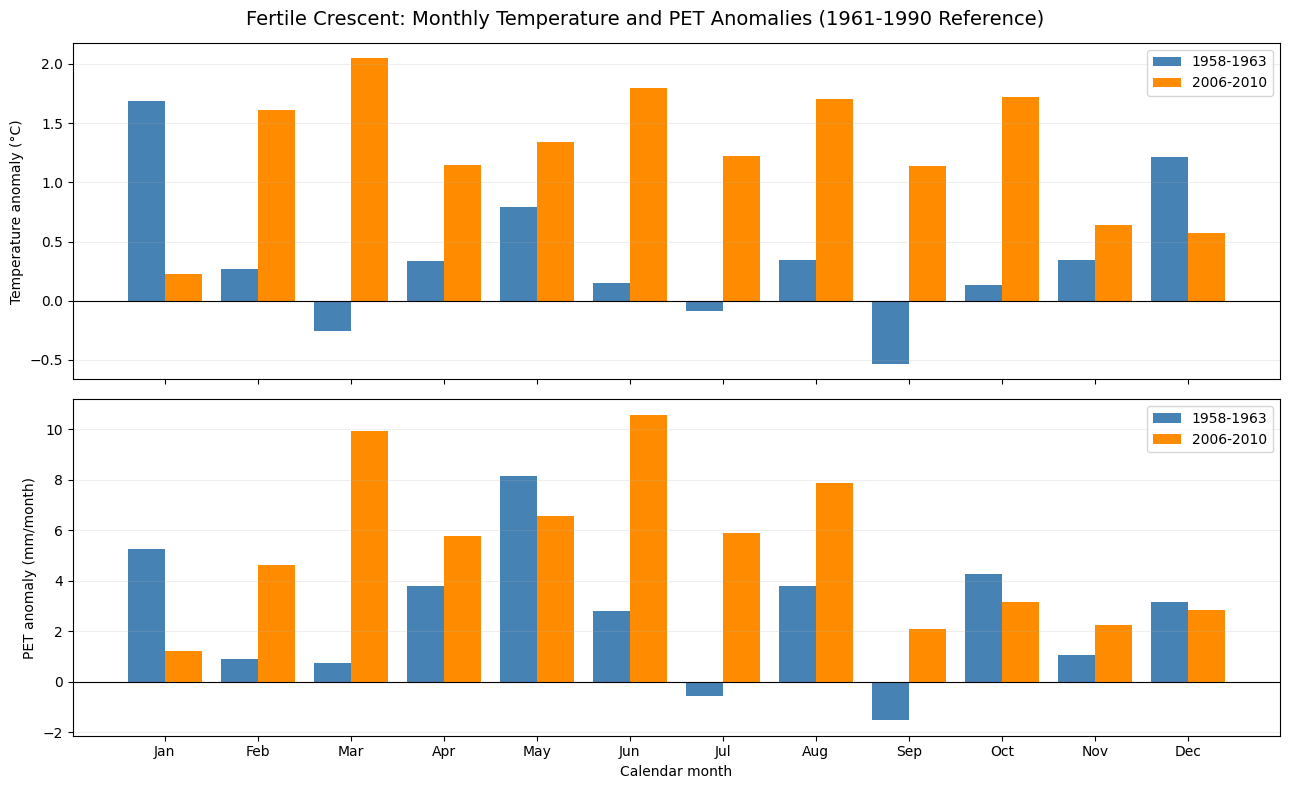

In [ ]:
# CRU - Seasonal Anomalies during the Two Droughts

months = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
          'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

month_numbers = np.arange(1, 13)

fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)

variables = [
    ('temp_anomaly', 'Temperature anomaly (°C)'),
    ('pet_anomaly', 'PET anomaly (mm/month)')
]

for ax, (column, ylabel) in zip(axes, variables):

    # averaging the anomalies for each calendar month
    earlier_monthly = earlier_cru.groupby(
        earlier_cru.index.month
    )[column].mean().reindex(month_numbers)

    modern_monthly = modern_cru.groupby(
        modern_cru.index.month
    )[column].mean().reindex(month_numbers)

    # plotting the two drought periods side by side
    ax.bar(month_numbers - 0.2, earlier_monthly,
           width=0.4, color='steelblue',
           label='1958-1963')

    ax.bar(month_numbers + 0.2, modern_monthly,
           width=0.4, color='darkorange',
           label='2006-2010')

    # marking the historical average (zero anomaly)
    ax.axhline(0, color='black', linewidth=0.8)

    ax.set_ylabel(ylabel)
    ax.grid(axis='y', alpha=0.2)
    ax.legend()

axes[1].set_xticks(month_numbers)
axes[1].set_xticklabels(months)
axes[1].set_xlabel('Calendar month')

fig.suptitle(
    'Fertile Crescent: Monthly Temperature and PET Anomalies (1961-1990 Reference)',
    fontsize=14
)

plt.tight_layout()
plt.savefig('cru_seasonal_anomalies.png', dpi=200, bbox_inches='tight')
plt.show()


## **AQUASTAT Irrigation and Water-Use Context**

To examine the water-management context surrounding Syria’s 2006–2010 drought, I used national AQUASTAT data from FAO. I initially reviewed all available variables, including agricultural water withdrawal, total water withdrawal, municipal water withdrawal, irrigation area, renewable water resources, and water stress.

However, the data-quality flags showed that many withdrawal values during the drought period were estimated or imputed, and several repeated exactly across multiple years. Because of that, I decided not to treat those series as strong evidence of year-to-year change.

Instead, I focused on two irrigation variables that showed clearer variation during the drought years: area equipped for irrigation by groundwater and total area equipped for irrigation. These variables are measured in thousand hectares and describe irrigation infrastructure rather than actual water use.

To assess change around the drought, I compared the values for 2004, 2006, 2009, and 2010 and calculated percentage changes across those intervals. I also plotted the full 1993–2014 series and marked imputed values separately from non-imputed values.

This analysis provides context for how irrigation infrastructure changed during the drought period, but it does not establish that drought caused those changes, nor does it measure actual irrigation activity or groundwater extraction.

In [ ]:
# AQUASTAT - Changes in Irrigation Equipped Area

import pandas as pd

# selecting the two relevant irrigation measurements
area_variables = [
    'Area equipped for irrigation by groundwater',
    'Area equipped for irrigation: total'
]

irrigation = df_aqua[
    df_aqua['Variable'].isin(area_variables)
].copy()

# checking for duplicate records
if irrigation.duplicated(['Variable', 'Year']).any():
    raise ValueError('Duplicate variable-year records found.')

# creating a table of annual values
area_table = irrigation.pivot(
    index='Variable', columns='Year', values='Value'
)

# selecting years relevant to the drought
years = [2004, 2006, 2009, 2010]
area_summary = area_table[years].copy()

# calculating changes over selected periods
area_summary['Change 2004-2009 (%)'] = (
    (area_summary[2009] / area_summary[2004] - 1) * 100
)

area_summary['Change 2006-2009 (%)'] = (
    (area_summary[2009] / area_summary[2006] - 1) * 100
)

area_summary['Change 2004-2010 (%)'] = (
    (area_summary[2010] / area_summary[2004] - 1) * 100
)

print('IRRIGATION AREA COMPARISON (1000 ha)')
print(area_summary.round(1).to_string())

# showing the original data flags alongside these observations
area_flags = irrigation[
    irrigation['Year'].isin(years)
].pivot(index='Variable', columns='Year', values='Symbol')

print('\nORIGINAL DATA FLAGS')
print(area_flags.to_string())


IRRIGATION AREA COMPARISON (1000 ha)
Year                                           2004    2006    2009    2010  Change 2004-2009 (%)  Change 2006-2009 (%)  Change 2004-2010 (%)
Variable                                                                                                                                     
Area equipped for irrigation by groundwater   864.7   851.1   656.2   726.8                 -24.1                 -22.9                 -15.9
Area equipped for irrigation: total          1438.7  1401.8  1238.3  1341.0                 -13.9                 -11.7                  -6.8

ORIGINAL DATA FLAGS
Year                                        2004 2006 2009 2010
Variable                                                       
Area equipped for irrigation by groundwater    A    A    A    A
Area equipped for irrigation: total            E    E    E    E


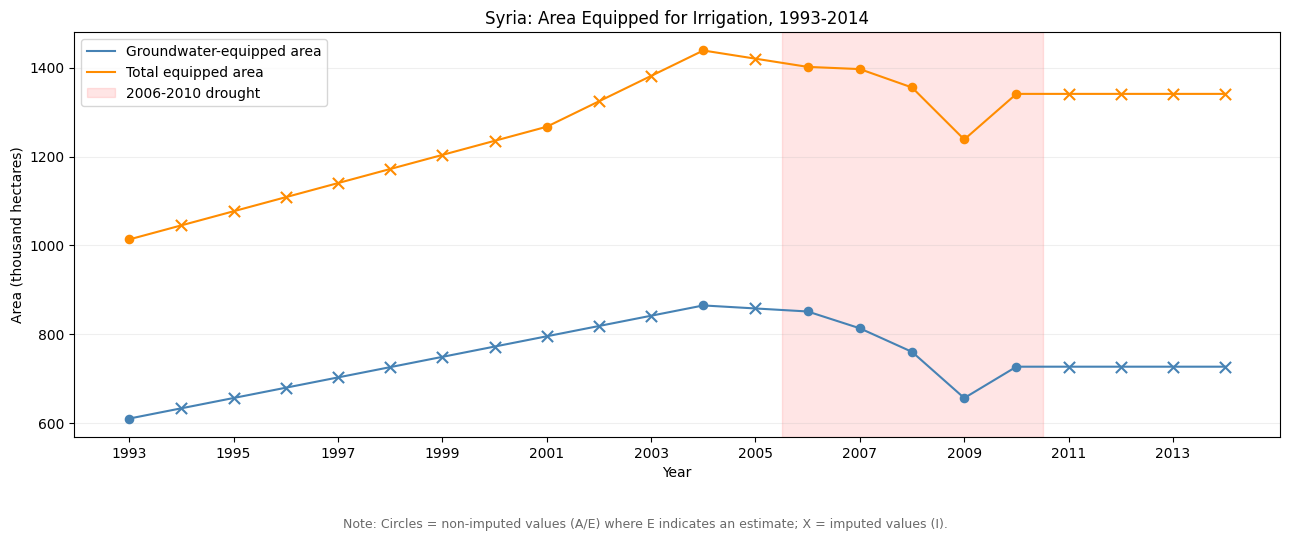

In [ ]:
# AQUASTAT - Historical Irrigation Equipped Area

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(13, 5.5))

variables = [
    ('Area equipped for irrigation by groundwater',
     'Groundwater-equipped area', 'steelblue'),
    ('Area equipped for irrigation: total',
     'Total equipped area', 'darkorange')
]

for variable, label, color in variables:

    data = irrigation[
        irrigation['Variable'] == variable
    ].sort_values('Year')

    # connecting the annual values with a line
    ax.plot(data['Year'], data['Value'],
            color=color, linewidth=1.5, label=label)

    # separating imputed and non-imputed values
    non_imputed = data[data['Symbol'] != 'I']
    imputed = data[data['Symbol'] == 'I']

    # circles for non-imputed values
    ax.scatter(non_imputed['Year'], non_imputed['Value'],
               color=color, marker='o', s=35, zorder=5)

    # X markers for imputed values
    ax.scatter(imputed['Year'], imputed['Value'],
               color=color, marker='x', s=65,
               linewidths=1.5, zorder=5)

# highlighting the drought period
ax.axvspan(2005.5, 2010.5,
           color='red', alpha=0.10,
           label='2006-2010 drought')

ax.set_title('Syria: Area Equipped for Irrigation, 1993-2014')
ax.set_xlabel('Year')
ax.set_ylabel('Area (thousand hectares)')
ax.set_xticks(range(1993, 2015, 2))
ax.grid(axis='y', alpha=0.2)
ax.legend()

# explaining the two marker types
fig.text(
    0.5, 0.025,
    'Note: Circles = non-imputed values (A/E) where E indicates an estimate; X = imputed values (I).',
    ha='center', va='bottom', fontsize=9, color='dimgray'
)

plt.tight_layout(rect=[0, 0.09, 1, 1])

plt.savefig('aquastat_irrigation.png',
            dpi=200, bbox_inches='tight')
plt.show()


## **UN Population Data**

To examine demographic changes surrounding the 2006–2010 drought, I used annual population estimates from the UN Population Data Portal for 1950–2014. The dataset contains three indicators for the Cities and towns category: population, percentage of the total population, and annual population growth rate. All observations are model-based estimates rather than direct annual population counts.

I calculated annual logarithmic growth rates from consecutive population estimates and compared average growth during 2006–2010 with the preceding five years (2001–2005). I also used 1996–2005 as a longer historical comparison period and examined individual years to identify changes that might be hidden by five-year averages.

The growth rates calculated from population counts did not always agree with the UN's separately reported annual growth-rate indicator. I therefore used the rates calculated from consecutive population estimates for my main comparison and figures, while retaining the discrepancy as a methodological limitation.

I created two figures: one showing the estimated population and population share in cities and towns from 1950–2014, and another showing annual population growth from 1990–2014. Both distinguish the 2006–2010 drought from the subsequent conflict period beginning in 2011.

Importantly, the Cities and towns category follows the UN's standardized degree-of-urbanization classification, rather than necessarily matching Syria's national administrative definition of urban areas.
These demographic estimates cannot independently measure rural-to-urban migration or identify its causes. These demographic estimates cannot independently measure rural-to-urban migration or identify its causes. Historical reporting can therefore provide additional evidence about documented migration from drought-affected rural communities, while the UN data are used here only to describe the observed demographic trends.

In [ ]:
# UN Population Data - Urbanisation & Growth Analysis

import pandas as pd
import numpy as np

population = df_population.copy()
population = population.rename(columns={'Time': 'Year'})

# checking required fields and duplicate indicator-year records
if population.duplicated(['IndicatorName', 'Year']).any():
    raise ValueError('Duplicate indicator-year records found.')

# organizing the three indicators by year
un_data = population.pivot(
    index='Year',
    columns='IndicatorName',
    values='Value'
).sort_index()

# giving the indicators shorter names
un_data = un_data.rename(columns={
    'Population by degree of urbanization': 'population',
    'Percentage of population by degree of urbanization': 'population_share',
    'Annual rate of population change by degree of urbanization': 'reported_growth'
})

# checking the historical record
print('Year range:', un_data.index.min(), 'to', un_data.index.max())
print('Missing values:')
print(un_data.isna().sum())

if un_data.isna().any().any():
    raise ValueError('Missing values in the UN population data.')

# calculating annual growth from population counts
un_data['calculated_growth'] = (
    np.log(un_data['population'] / un_data['population'].shift(1)) * 100
)

# comparing calculated growth with the reported UN indicator
un_data['growth_difference'] = (
    un_data['reported_growth'] - un_data['calculated_growth']
)

print('\nGROWTH RATE COMPARISON, 2004-2010')
print(
    un_data.loc[2004:2010, [
        'reported_growth', 'calculated_growth', 'growth_difference'
    ]].round(2).to_string()
)

# comparing pre-drought and drought-period growth
growth_before = un_data.loc[2001:2005, 'calculated_growth'].mean()
growth_during = un_data.loc[2006:2010, 'calculated_growth'].mean()
growth_before_10yr = un_data.loc[1996:2005, 'calculated_growth'].mean()

print('\nAVERAGE ANNUAL POPULATION GROWTH')
print('2001-2005:', round(growth_before, 2), '%')
print('2006-2010:', round(growth_during, 2), '%')
print('1996-2005:', round(growth_before_10yr, 2), '%')
print(
    'Change from five-year baseline:',
    round(growth_during - growth_before, 2),
    'percentage points'
)

# comparing selected years
selected_years = [2001, 2005, 2006, 2007, 2008, 2009, 2010, 2014]

population_summary = un_data.loc[selected_years, [
    'population', 'population_share', 'calculated_growth'
]].copy()

population_summary['population'] = population_summary['population'] / 1_000_000

population_summary = population_summary.rename(columns={
    'population': 'Cities and towns population (millions)',
    'population_share': 'Population share (%)',
    'calculated_growth': 'Annual growth (%)'
})

print('\nSELECTED POPULATION STATISTICS')
print(population_summary.round(2).to_string())

# measuring change from 2005 to 2010
population_change = (
    un_data.loc[2010, 'population'] /
    un_data.loc[2005, 'population'] - 1
) * 100

share_change = (
    un_data.loc[2010, 'population_share'] -
    un_data.loc[2005, 'population_share']
)

print('\nCHANGE FROM 2005 TO 2010')
print('Population change (%):', round(population_change, 2))
print(
    'Population share change (percentage points):',
    round(share_change, 2)
)

Year range: 1950 to 2014
Missing values:
IndicatorName
reported_growth     0
population_share    0
population          0
dtype: int64

GROWTH RATE COMPARISON, 2004-2010
IndicatorName  reported_growth  calculated_growth  growth_difference
Year                                                                
2004                      3.09               3.00               0.09
2005                      3.36               3.07               0.29
2006                      6.95               5.35               1.60
2007                      7.32               7.14               0.18
2008                      1.67               4.44              -2.77
2009                      3.11               2.40               0.71
2010                      2.29               3.05              -0.76

AVERAGE ANNUAL POPULATION GROWTH
2001-2005: 3.02 %
2006-2010: 4.48 %
1996-2005: 3.21 %
Change from five-year baseline: 1.46 percentage points

SELECTED POPULATION STATISTICS
IndicatorName  Cities and towns pop

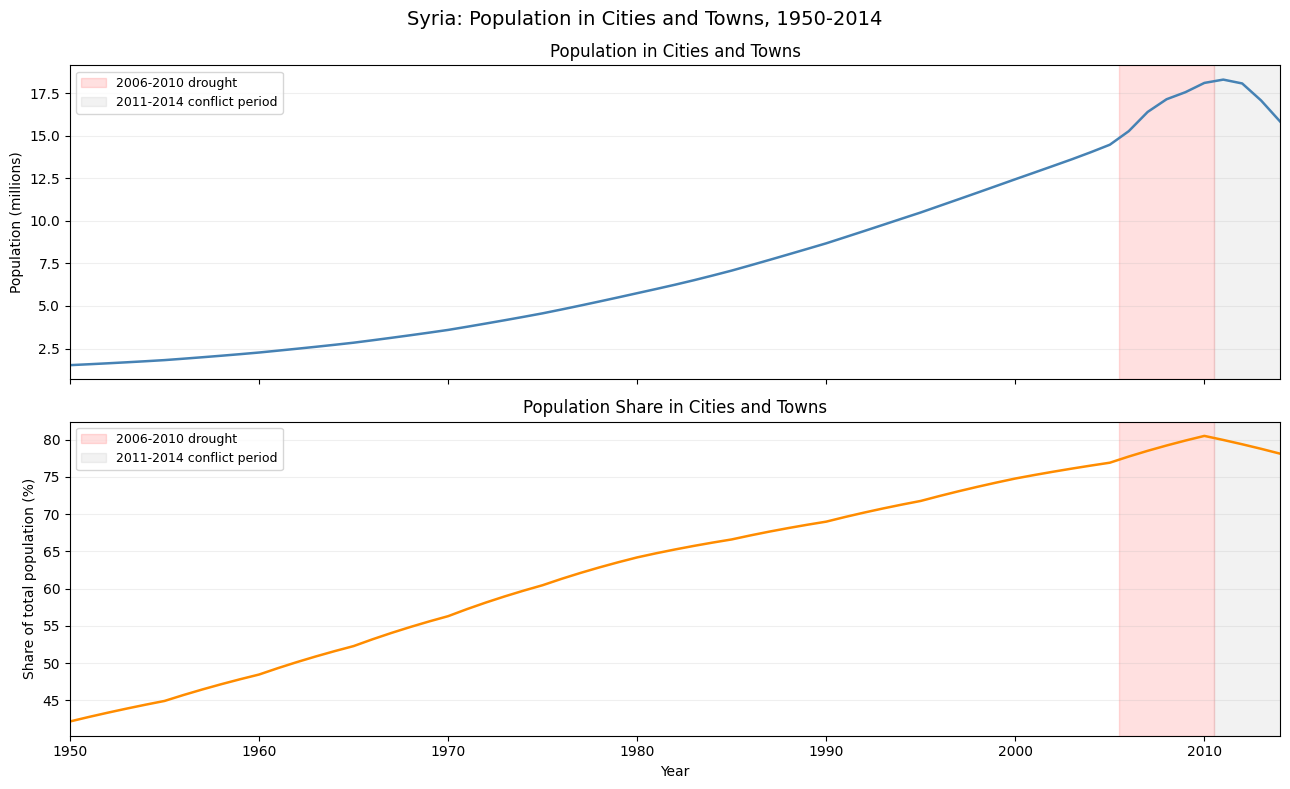

In [ ]:
# UN - City & Town Populations (1950-2014)

import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)

# plotting estimated population in millions
axes[0].plot(
    un_data.index,
    un_data['population'] / 1000000,
    color='steelblue', linewidth=1.8
)

axes[0].set_ylabel('Population (millions)')
axes[0].set_title('Population in Cities and Towns')

# plotting the percentage of Syria's total population
axes[1].plot(
    un_data.index,
    un_data['population_share'],
    color='darkorange', linewidth=1.8
)

axes[1].set_ylabel('Share of total population (%)')
axes[1].set_title('Population Share in Cities and Towns')

# highlighting the drought and subsequent conflict period
for ax in axes:

    ax.axvspan(2005.5, 2010.5,
               color='red', alpha=0.12,
               label='2006-2010 drought')

    ax.axvspan(2010.5, 2014.5,
               color='gray', alpha=0.10,
               label='2011-2014 conflict period')

    ax.grid(axis='y', alpha=0.2)
    ax.legend(fontsize=9)

axes[1].set_xlabel('Year')
axes[1].set_xlim(1950, 2014)

fig.suptitle(
    'Syria: Population in Cities and Towns, 1950-2014',
    fontsize=14
)

plt.tight_layout()
plt.savefig('un_urban_population.png',
            dpi=200, bbox_inches='tight')
plt.show()


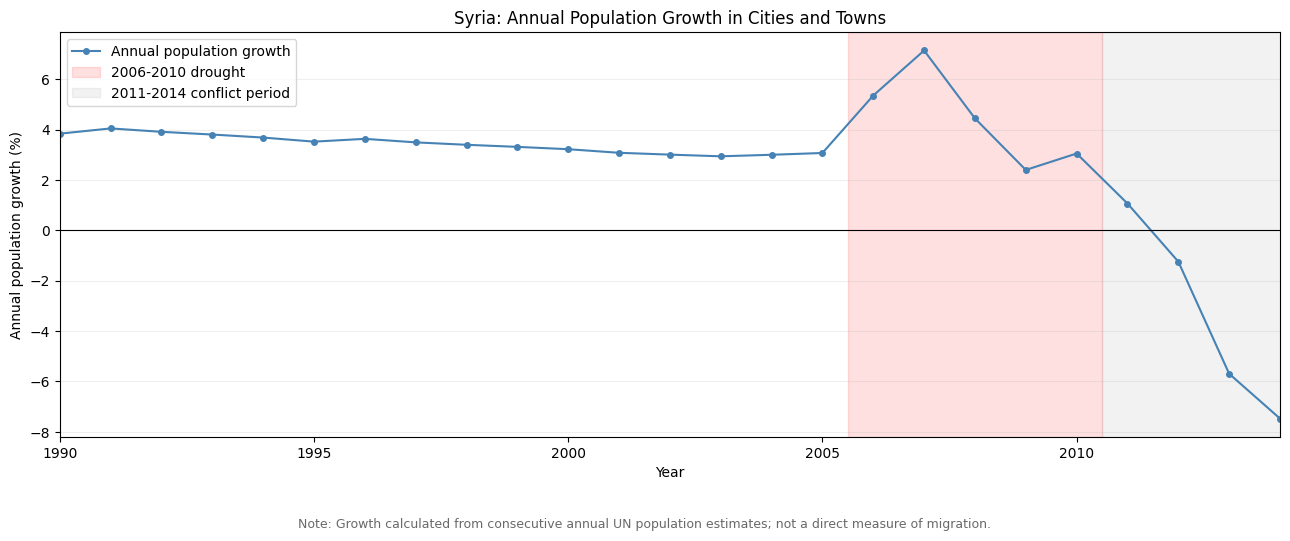

In [ ]:
# UN - Annual Population Growth in Cities and Towns

fig, ax = plt.subplots(figsize=(13, 5.5))

# plotting annual growth calculated from population counts
ax.plot(
    un_data.index,
    un_data['calculated_growth'],
    color='steelblue',
    marker='o',
    markersize=4,
    linewidth=1.5,
    label='Annual population growth'
)

# highlighting the drought interval
ax.axvspan(2005.5, 2010.5,
           color='red', alpha=0.12,
           label='2006-2010 drought')

# distinguishing the subsequent conflict years
ax.axvspan(2010.5, 2014.5,
           color='gray', alpha=0.10,
           label='2011-2014 conflict period')

ax.axhline(0, color='black', linewidth=0.8)

ax.set_title('Syria: Annual Population Growth in Cities and Towns')
ax.set_xlabel('Year')
ax.set_ylabel('Annual population growth (%)')
ax.set_xlim(1990, 2014)
ax.grid(axis='y', alpha=0.2)
ax.legend()

# documenting the calculation directly on the figure
fig.text(
    0.5, 0.025,
    'Note: Growth calculated from consecutive annual UN population estimates; not a direct measure of migration.',
    ha='center', va='bottom',
    fontsize=9, color='dimgray'
)

plt.tight_layout(rect=[0, 0.09, 1, 1])

plt.savefig('un_population_growth.png',
            dpi=200, bbox_inches='tight')
plt.show()
